# Session 12 - Workshop: Bias Audit Report on my doctoral data (MTC toll-station traffic)

**Research Methods & Scientific Integrity in AI** - Doctoral Program in Deep Technologies, UNMSM
**Instructor:** Dr. Loveleen Gaur
**Student:** Moisés Evangelista Gamarra (Student Code: 26207275)

This notebook applies the Session 12 workshop protocol (*Build a Bias Audit Report*) to the dataset of my doctoral project:
**"Flujo Vehicular Registrado en las Unidades de Peaje de la Red Vial Nacional (2014 - 2026 I)"**, published by the Ministry of Transport and Communications (MTC) on Peru's National Open Data Portal. The target is `VEH_IMD`, the average daily vehicle count of a toll station in a month.

### Toolkit rule
| Task type | Toolkit | Why |
|---|---|---|
| **Classification** (binary target) | **IBM AI Fairness 360** | Group metrics are defined on favorable / unfavorable labels (disparate impact, equal opportunity) |
| **Regression** (continuous target) | **Microsoft Fairlearn** | `MetricFrame` handles any loss per group, and `ExponentiatedGradient` + `BoundedGroupLoss` mitigates regression models |

`VEH_IMD` is continuous, so the audit runs with **Fairlearn**. Section 11 keeps an AIF360 branch that runs automatically if the target is ever binary.

### Same 12 sections as the workshop notebook
| Workshop section | What it becomes for a regression audit |
|---|---|
| 3. Direction of "favorable" | Direction of **harm**: which error sign hurts a region (under-forecasting) |
| 4. Bias in the raw data | Representation and forecastability of each region, before any model |
| 6. Baseline | Ridge regression on log traffic, chronological split |
| 7. ONE mitigation | Fairlearn **ExponentiatedGradient + BoundedGroupLoss** (in-processing) |
| 8. Before vs after | Same metrics on the same held-out test year |
| 9. Noise check | **10 rolling forecast origins** (the time-series version of the workshop's 10 splits) + toll-station cluster bootstrap |
| 10. Cross-check | Fairlearn vs pandas, and the **scale trap** (vehicles vs percent) |
| 12. Report | Generated automatically as an **English Word document** from the numbers of this run |

> **Run:** `Runtime > Run all`. Section 3.1 opens an upload dialog for the MTC CSV; the file is stored in `data/` of the project folder with an MD5 manifest and committed to the project's Git repository. Nothing in the report is typed by hand: every number comes from the cells below.

## 1. Setup
Installs Fairlearn (regression audit), AIF360 (classification branch) and `python-docx` (Word report).

In [1]:
!pip -q install fairlearn aif360 python-docx "pandas<3"

import os, re, io, sys, json, glob, time, zipfile, hashlib, subprocess, unicodedata, warnings, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

import sklearn, fairlearn
from sklearn.linear_model import Ridge
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from fairlearn.metrics import MetricFrame
from fairlearn.reductions import ExponentiatedGradient, BoundedGroupLoss, AbsoluteLoss

IN_COLAB = "google.colab" in sys.modules
print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | fairlearn {fairlearn.__version__} | Colab: {IN_COLAB}")

pandas 2.2.3 | scikit-learn 1.6.1 | fairlearn 0.15.0 | Colab: True


## 2. Config
One cell drives the whole notebook. The column names are detected automatically; if detection fails, write them in `COLS`.

* **Audit groups.** The sensitive attribute is the **natural macro-region** of the road each toll serves (Costa / Sierra / Selva). Toll stations are not people, but road-investment decisions based on these forecasts are allocated to the people who live in each region, and Peru's road network has historically concentrated investment on the coast. The reference group is **Costa**; the comparison group is the **Interior** (Sierra + Selva).
* **How the region is assigned (verifiable, not by eye).** `CODIGO_PEAJE` encodes the national route (e.g. `04PE1SCAM1` = route PE-1S). Tolls on the three **longitudinal** axes take the axis's region: PE-1 Panamericana → Costa, PE-3 Longitudinal de la Sierra → Sierra, PE-5 Longitudinal de la Selva → Selva. Tolls on **transversal** routes take the predominant region of their department (`REGION_MAP`), with documented exceptions in `STATION_REGION_OVERRIDE`. Classifying by department alone would put the Panamericana tolls of Arequipa and Áncash in the Sierra.
* **Anomalous regime.** Months 2020-03 to 2021-06 (COVID-19 restrictions) are excluded from training, following my ITFF experiments.

In [2]:
CONFIG = {
    "CSV_NAME": "Flujo vehicular registrado en peajes_2014-2026_I.csv",
    "PROJECT_DIR": ("/content/Session12_MTC_Bias_Audit" if IN_COLAB
                    else os.path.abspath("session12_mtc_bias_audit")),   # project folder (Git repository)
    "OUTPUT_DIR": None,                    # None = <PROJECT_DIR>/outputs
    "TARGET": "VEH_IMD",
    "DUPLICATE_AGG": "sum",            # if a toll has several rows in one month
    "ANOMALY_WINDOW": ("2020-03-01", "2021-06-01"),
    "TEST_MONTHS": 12, "VALID_MONTHS": 12,
    "N_ORIGINS": 10, "ORIGIN_STEP_MONTHS": 3,   # 10 rolling forecast origins, 3 months apart
    "REFERENCE_REGION": "COSTA",
    "RIDGE_ALPHA": 1.0,
    "BOUND_FACTORS": [1.0, 0.9, 0.8, 0.7],   # candidate bounds = factor x baseline training loss
    "MAX_OVERALL_INCREASE": 1.05,          # selection rule: overall validation MAPE may rise at most 5 %
    "N_BOOT": 1000, "SEED": 42,
    "STUDENT": "Moisés Evangelista Gamarra", "STUDENT_CODE": "26207275",
    "INSTRUCTOR": "Dr. Loveleen Gaur",
    "COURSE": "Research Methods and Scientific Integrity in AI",
    "PROGRAM": "Doctoral Program in Deep Technologies, UNMSM",
}
COLS = {"target": None, "station": None, "station_name": None, "department": None,
        "date": None, "year": None, "month": None}      # manual overrides if needed

REGION_BY_ROUTE = {1: "COSTA", 3: "SIERRA", 5: "SELVA"}      # longitudinal national routes
STATION_REGION_OVERRIDE = {"Matarani Concesión": "COSTA",     # PE-34M, port access road on the coast
                           "Corcona-Concesión": "SIERRA"}     # PE-22C, Carretera Central in the Lima highlands
REGION_MAP = {
    "COSTA":  ["TUMBES", "PIURA", "LAMBAYEQUE", "LA LIBERTAD", "LIMA", "CALLAO", "ICA", "MOQUEGUA", "TACNA"],
    "SIERRA": ["ANCASH", "CAJAMARCA", "HUANUCO", "PASCO", "JUNIN", "HUANCAVELICA", "AYACUCHO",
               "APURIMAC", "CUSCO", "PUNO", "AREQUIPA"],
    "SELVA":  ["AMAZONAS", "SAN MARTIN", "LORETO", "UCAYALI", "MADRE DE DIOS"],
}
# Overrides used only to test this notebook outside Colab
for k in ("OUTPUT_DIR", "PROJECT_DIR"):
    if os.environ.get(f"MTC_{k}"): CONFIG[k] = os.environ[f"MTC_{k}"]
CONFIG["OUTPUT_DIR"] = os.path.abspath(CONFIG["OUTPUT_DIR"] or os.path.join(CONFIG["PROJECT_DIR"], "outputs"))

SEED = CONFIG["SEED"]; np.random.seed(SEED)
OUT = Path(CONFIG["OUTPUT_DIR"]); FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
REF = CONFIG["REFERENCE_REGION"]
REGION_COLORS = {"COSTA": "#2a78d6", "SIERRA": "#eb6834", "SELVA": "#1baf7a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
print("Output folder:", OUT)

Output folder: /content/Session12_MTC_Bias_Audit/outputs


## 3. Load the data, identify the task type, and pin down the direction of harm
**3.1 Secure loading of the MTC dataset.** The first cell creates the project folder and a small `commit()` helper (it reuses a `PROJ` and a `commit()` already defined in the session, if any). The second cell is my data-loading cell: it opens the upload dialog, stores the CSV in `data/` under a clean name (no spaces, no " (2)" from repeated uploads), writes `data/DATA_MANIFEST.json` with the MD5 checksum and the source URL, and commits both files, so the report can be traced to the exact file that produced it.

In [3]:
# Project folder and Git helper (only defined if the session does not already provide them)
PROJ = globals().get("PROJ") or CONFIG["PROJECT_DIR"]
os.makedirs(os.path.join(PROJ, "data"), exist_ok=True)

def _git(*args):
    return subprocess.run(["git", "-C", PROJ, *args], capture_output=True, text=True)

if "commit" not in globals():
    def commit(message, *paths):
        """git add + commit inside PROJ; prints the short hash, never stops the notebook."""
        if _git("rev-parse", "--is-inside-work-tree").returncode != 0:
            _git("init", "-q")
        if not _git("config", "user.name").stdout.strip():
            _git("config", "user.name", CONFIG["STUDENT"])
            _git("config", "user.email", f"{CONFIG['STUDENT_CODE']}@local")
        _git("add", "--", *paths)
        r = _git("commit", "-q", "-m", message)
        if r.returncode == 0:
            print("🔖 Commit:", _git("rev-parse", "--short", "HEAD").stdout.strip(), "|", message)
        elif "nothing to commit" in (r.stdout + r.stderr):
            print("🔖 No changes to commit (same file already versioned).")
        else:
            print("⚠️ git commit failed:", (r.stderr or r.stdout).strip()[:300])
print("Project folder:", PROJ)

Project folder: /content/Session12_MTC_Bias_Audit


In [4]:
# ============================================================
# SECURE LOADING OF THE MTC DATASET
# ============================================================
os.chdir(PROJ)
COMMIT_DATA = True        # MTC open data: versioned together with the code
DATA_SRC = os.environ.get("MTC_CSV_PATH", "")   # outside Colab only: local path of the CSV

try:
    from google.colab import files
    print("📂 Select the MTC CSV file...")
    uploaded = files.upload()          # Colab also saves it in the current folder
    if not uploaded:
        raise FileNotFoundError("❌ No file was selected.")
    filename = next(iter(uploaded))
    contenido = uploaded[filename]
except ImportError:
    assert DATA_SRC and os.path.exists(DATA_SRC), "Outside Colab, define DATA_SRC"
    filename, contenido = os.path.basename(DATA_SRC), open(DATA_SRC, "rb").read()

# clean name inside data/ (no spaces, no " (2)" from repeated uploads)
limpio = re.sub(r"\s*\(\d+\)(?=\.\w+$)", "", os.path.basename(filename))
limpio = re.sub(r"[^\w.\-]+", "_", limpio)
DATA = os.path.join("data", limpio)
with open(DATA, "wb") as f:
    f.write(contenido)
if os.path.exists(filename) and os.path.abspath(filename) != os.path.abspath(DATA):
    os.remove(filename)                # removes the copy that files.upload() leaves in the repo root

DATA_MD5 = hashlib.md5(open(DATA, "rb").read()).hexdigest()
json.dump({"file": DATA, "md5": DATA_MD5,
           "source": "MTC · Portal Nacional de Datos Abiertos · Flujo vehicular en unidades de peaje",
           "url": "https://www.datosabiertos.gob.pe/dataset/flujo-vehicular-registrado-en-las-unidades-de-peaje-de-la-red-vial-nacional-2014-%E2%80%93-2026-i"},
          open("data/DATA_MANIFEST.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
print("📁 Dataset:", DATA, "| 🔐 MD5:", DATA_MD5)

if COMMIT_DATA:
    commit("Add MTC dataset and MD5 manifest", DATA, "data/DATA_MANIFEST.json")
else:
    open(".gitignore", "a").write(DATA + "\n")
    commit("Add MD5 manifest (data kept out of Git)", ".gitignore", "data/DATA_MANIFEST.json")

📂 Select the MTC CSV file...


Saving Flujo vehicular registrado en peajes_2014-2026_I.csv to Flujo vehicular registrado en peajes_2014-2026_I.csv
📁 Dataset: data/Flujo_vehicular_registrado_en_peajes_2014-2026_I.csv | 🔐 MD5: bb6e20c8830af2511da8746ca42f6aa3
🔖 Commit: 99bbc33 | Add MTC dataset and MD5 manifest


**3.2** reads the stored CSV, detects the columns, rebuilds a monthly date and builds a clean toll-by-month panel.

In [5]:
def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"[^A-Z0-9]", "", s.upper())

def read_csv_robust(path_or_buffer):
    last = None
    for enc in ("utf-8-sig", "latin-1"):
        try:
            if hasattr(path_or_buffer, "seek"): path_or_buffer.seek(0)
            return pd.read_csv(path_or_buffer, sep=None, engine="python", encoding=enc)
        except (UnicodeDecodeError, pd.errors.ParserError) as e:
            last = e
    raise last

CSV_PATH = os.path.join(PROJ, DATA)        # set by the data-loading cell (3.1)
raw = read_csv_robust(CSV_PATH)
raw.columns = [str(c).strip() for c in raw.columns]
print(f"File: {CSV_PATH}\nShape: {raw.shape}")
display(raw.head())

def find(cands, override):
    if override: return override
    m = {norm(c): c for c in raw.columns}
    for c in cands:
        if norm(c) in m: return m[norm(c)]
    return None

C_TARGET = find([CONFIG["TARGET"]], COLS["target"])
C_STATION = find(["CODIGO_PEAJE", "COD_PEAJE", "ID_PEAJE", "CODIGO", "PEAJE", "NOMBRE_PEAJE", "UNIDAD_PEAJE"], COLS["station"])
C_NAME = find(["NOMBRE_PEAJE", "PEAJE", "UNIDAD_PEAJE", "NOMBRE"], COLS["station_name"]) or C_STATION
C_DEPT = find(["DEPARTAMENTO", "DEPARTAMENTO_PEAJE", "DPTO", "REGION"], COLS["department"])
C_DATE = find(["FECHA", "PERIODO", "FECHA_REGISTRO", "FECHA_CORTE_MES", "MES_ANIO", "DATE", "PERIOD"], COLS["date"])
C_YEAR = find(["ANIO", "AÑO", "ANO", "YEAR"], COLS["year"])
C_MONTH = find(["MES", "MONTH", "NUM_MES", "NRO_MES"], COLS["month"])
detected = {"target": C_TARGET, "station": C_STATION, "station name": C_NAME, "department": C_DEPT,
            "date": C_DATE, "year": C_YEAR, "month": C_MONTH}
for k, v in detected.items(): print(f"  {k:13s}: {v}")
if C_TARGET is None or C_STATION is None or C_DEPT is None or (C_DATE is None and not (C_YEAR and C_MONTH)):
    raise ValueError("Set the missing column names in COLS (Section 2) using the list printed above.")

File: /content/Session12_MTC_Bias_Audit/data/Flujo_vehicular_registrado_en_peajes_2014-2026_I.csv
Shape: (11532, 25)


,ADMINIST,CODIGO_PEAJE,DEPARTAMENTO,NOMBRE_PEAJE,VEH_LIGEROS_TAR_DIF,VEH_LIGEROS_AUTOMOVILES,VEH_PESADOS_TAR_DIF,VEH_PESADOS_2E,VEH_PESADOS_3E,VEH_PESADOS_4E,...,VEH_PESADOS_TOTAL,VEH_PESADOS_IMD,VEH_TOTAL,VEH_IMD,ANIO,MES,PERIODO,Unnamed: 22,Unnamed: 23,Unnamed: 24
0,Concesionado,22PE5NACS1,San Martín,Aguas Claras,2 099,8 070,0,2 586,2 374,720,...,9 515,307,19 684,635,2014,1,201401,NaN,NaN,NaN
1,Concesionado,04PE1SCAM1,Arequipa,Camaná,0,24 644,0,6 502,4 622,1 654,...,24 730,798,49 374,1 593,2014,1,201401,NaN,NaN,NaN
2,Concesionado,21PE3SCRO1,Puno,Caracoto,33 643,82 139,5 797,17 981,5 307,1 150,...,37 326,1 204,153 108,4 939,2014,1,201401,NaN,NaN,NaN
3,Concesionado,12PE3NCRA1,Junín,Casaracra-Concesión,10,46 944,0,16 981,18 585,4 463,...,62 622,2 020,109 576,3 535,2014,1,201401,NaN,NaN,NaN
4,Concesionado,08PE3SCSC1,Cusco,Ccasacancha (Huillque),0,23 831,0,4 709,3 941,447,...,13 906,449,37 737,1 217,2014,1,201401,NaN,NaN,NaN


  target       : VEH_IMD
  station      : CODIGO_PEAJE
  station name : NOMBRE_PEAJE
  department   : DEPARTAMENTO
  date         : PERIODO
  year         : ANIO
  month        : MES


In [6]:
MONTHS_ES = {"ENERO": 1, "FEBRERO": 2, "MARZO": 3, "ABRIL": 4, "MAYO": 5, "JUNIO": 6, "JULIO": 7, "AGOSTO": 8,
             "SETIEMBRE": 9, "SEPTIEMBRE": 9, "OCTUBRE": 10, "NOVIEMBRE": 11, "DICIEMBRE": 12}

def to_number(s):
    if pd.api.types.is_numeric_dtype(s): return s.astype(float)
    x = pd.to_numeric(s, errors="coerce")
    if x.isna().mean() > 0.05:      # thousands separators or decimal commas
        t = s.astype(str).str.strip().str.replace(r"\s", "", regex=True)
        alt = pd.to_numeric(t.str.replace(".", "", regex=False).str.replace(",", ".", regex=False), errors="coerce")
        x = alt if alt.notna().mean() > x.notna().mean() else x
    return x

def build_date():
    if C_YEAR and C_MONTH and (C_DATE is None or C_DATE in (C_YEAR, C_MONTH)):
        m = raw[C_MONTH]
        m = pd.to_numeric(m, errors="coerce").fillna(m.astype(str).map(lambda v: MONTHS_ES.get(norm(v))))
        return pd.to_datetime(dict(year=pd.to_numeric(raw[C_YEAR], errors="coerce"), month=m, day=1), errors="coerce")
    s = raw[C_DATE]
    t = s.astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    d = pd.to_datetime(t, format="%Y%m", errors="coerce")
    if d.notna().mean() < 0.6:
        d = pd.to_datetime(s, errors="coerce", dayfirst=True)
    return d.dt.to_period("M").dt.to_timestamp()

def to_region(dept):
    key = norm(dept)
    for region, depts in REGION_MAP.items():
        if key in {norm(x) for x in depts}: return region
    return "UNMAPPED"

base = pd.DataFrame({
    "station": raw[C_STATION].astype(str).str.strip(),
    "name": raw[C_NAME].astype(str).str.strip(),
    "department": raw[C_DEPT].astype(str).str.strip().str.upper(),
    "date": build_date(),
    "y": to_number(raw[C_TARGET]),
})
n_raw = len(base)
base = base.dropna(subset=["date", "y"])
dup = int(base.duplicated(["station", "date"]).sum())
panel = (base.groupby(["station", "date"], as_index=False)
             .agg(y=("y", CONFIG["DUPLICATE_AGG"]), name=("name", "first"), department=("department", "first")))
zero_months = int((panel["y"] <= 0).sum())
panel = panel[panel["y"] > 0].copy()      # VEH_IMD = 0 means the toll did not operate that month: not a traffic measurement
ov = {norm(k): v for k, v in STATION_REGION_OVERRIDE.items()}
def assign_region(code, dept, name):
    if norm(name) in ov: return ov[norm(name)], "override"
    m = re.search(r"PE(\d+)", str(code))
    if m and int(m.group(1)) in REGION_BY_ROUTE: return REGION_BY_ROUTE[int(m.group(1))], f"route PE-{int(m.group(1))}"
    return to_region(dept), "department (transversal route)"
ra = [assign_region(c, d, n) for c, d, n in zip(panel["station"], panel["department"], panel["name"])]
panel["region"] = [r for r, _ in ra]; panel["region_source"] = [src for _, src in ra]
unmapped = sorted(panel.loc[panel["region"] == "UNMAPPED", "department"].unique())
panel = panel.sort_values(["station", "date"]).reset_index(drop=True)

COVERAGE = {"rows_in_file": n_raw, "rows_with_date_and_target": len(base), "station_months": len(panel),
            "duplicate_station_months_aggregated": dup, "zero_traffic_months_removed": zero_months,
            "stations": panel["station"].nunique(),
            "date_min": panel["date"].min().strftime("%Y-%m"), "date_max": panel["date"].max().strftime("%Y-%m"),
            "unmapped_departments": unmapped}
for k, v in COVERAGE.items(): print(f"  {k:38s}: {v}")
if unmapped:
    print("  WARNING: departments not in REGION_MAP are excluded from the fairness groups:", unmapped)
print("\nStations per region and assignment rule (check the classification here):")
REGION_ASSIGNMENT = (panel.drop_duplicates("station").groupby(["region", "region_source"])["name"]
                     .agg(n="count", toll_stations=lambda x: ", ".join(sorted(x.unique()))))
display(REGION_ASSIGNMENT)

  rows_in_file                          : 11532
  rows_with_date_and_target             : 11532
  station_months                        : 10690
  duplicate_station_months_aggregated   : 37
  zero_traffic_months_removed           : 805
  stations                              : 82
  date_min                              : 2014-01
  date_max                              : 2026-03
  unmapped_departments                  : []

Stations per region and assignment rule (check the classification here):


n  \
region region_source                        
COSTA  department (transversal route)  13   
       override                         1   
       route PE-1                      32   
SELVA  department (transversal route)   4   
       route PE-5                       4   
SIERRA department (transversal route)  15   
       override                         1   
       route PE-3                      12   

                                                                           toll_stations  
region region_source                                                                      
COSTA  department (transversal route)  Ciudad de Dios, Cuculí (Pomalca), Desvío Olmos...  
       override                                                       Matarani Concesión  
       route PE-1                      Atico, Camaná, Cancas, Chicama, Chilca, Chuluc...  
SELVA  department (transversal route)  Pedro Ruiz, Planchón, San Lorenzo, Unión Progreso  
       route PE-5                      Aguas Claras, Moyobamba, Pongo, Utcubamba (Bagua)  
SIERRA department (transversal route)  Chalhuapuquio (El Pedregal), Macusani, Pampa G...  
       override                                                        Corcona-Concesión  
       route PE-3                      Aguas Calientes, Ambo, Ayaviri, Caracoto, Casa...

**3.2 Task type and toolkit.** The rule from the top of the notebook is applied in code, not by hand.

In [7]:
y_values = panel["y"].dropna().unique()
TASK_TYPE = "classification" if set(np.unique(y_values)) <= {0, 1} else "regression"
TOOLKIT = "IBM AI Fairness 360" if TASK_TYPE == "classification" else "Microsoft Fairlearn"
print(f"Target {C_TARGET}: {len(y_values):,} distinct values, min {np.nanmin(y_values):,.1f}, max {np.nanmax(y_values):,.1f}")
print(f"TASK TYPE: {TASK_TYPE.upper()}  ->  toolkit: {TOOLKIT}")
assert TASK_TYPE == "regression", "Binary target detected: run the AIF360 branch in Section 11 instead."

Target VEH_IMD: 5,044 distinct values, min 1.0, max 37,357.0
TASK TYPE: REGRESSION  ->  toolkit: Microsoft Fairlearn


**3.3 Direction of harm (the regression version of "which label is favorable").** In a regression audit there is no favorable label, but there is a harmful **direction of error**, and getting its sign backwards reverses the meaning of every bias number, exactly as in COMPAS.

* Signed percentage error = (prediction − actual) / actual × 100. **Negative = under-forecast.**
* An **under-forecast** of traffic is the harmful direction for a region: planning, maintenance budgets and toll-lane staffing sized on a forecast that is too low leave that region's road users under-served. An over-forecast costs public money, but it does not deprive the region.

The assertion below fixes the sign convention in code, so it cannot flip silently.

In [8]:
def signed_pct_error(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return (p - y) / y * 100

def abs_pct_error(y, p):
    return np.abs(signed_pct_error(y, p))

assert signed_pct_error([100.0], [90.0])[0] < 0, "Sign convention broken: an under-forecast must be negative."
assert signed_pct_error([100.0], [110.0])[0] > 0
print("DIRECTION CONFIRMED")
print("  signed error < 0  = under-forecast = the region's traffic is under-estimated  (harmful direction)")
print("  signed error > 0  = over-forecast")

DIRECTION CONFIRMED
  signed error < 0  = under-forecast = the region's traffic is under-estimated  (harmful direction)
  signed error > 0  = over-forecast


**TODO (answered):**
- Sensitive attribute I am auditing: `natural macro-region of the toll's department (Costa / Sierra / Selva), derived from DEPARTAMENTO`
- Reference ("privileged") group: `Costa`  |  Comparison ("unprivileged") group: `Interior = Sierra + Selva`
- The *harmful* outcome in this task means: `a larger forecast error, and especially a systematic under-forecast (negative signed error), for a region's toll stations; investment and maintenance sized on those forecasts would under-serve that region.`
- If I had this direction backwards, my report would wrongly conclude that: `a region whose traffic is systematically under-estimated is "favoured" by the model, because its signed bias would be read as a benefit instead of a deficit.`

## 4. Measure bias in the raw data (before any model)
In regression there are no favorable base rates, so "bias already in the data" means two things that no model can fix by itself: **representation** (how many stations and months each region contributes) and **forecastability** (how volatile each region's series are). A model trained on all stations together learns mostly from the regions that dominate the data.

,Region,stations,station_months,median_IMD,share_of_rows,median_volatility
0,COSTA,46,6019,2012.0,56.3,15.3
1,SIERRA,28,3512,1292.5,32.9,16.0
2,SELVA,8,1159,832.0,10.8,12.8


median_volatility = median over stations of the s.d. of the monthly log change, in % (COVID window excluded).


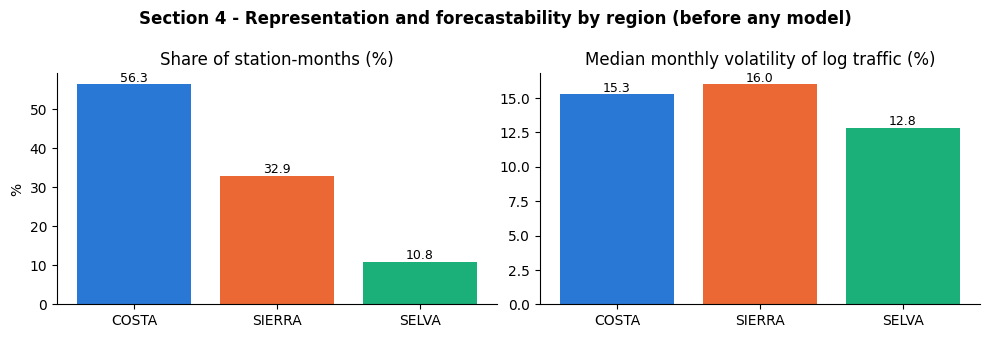

In [9]:
anom0, anom1 = map(pd.Timestamp, CONFIG["ANOMALY_WINDOW"])
p_ok = panel[panel["region"] != "UNMAPPED"].copy()
p_ok["logy"] = np.log1p(p_ok["y"].clip(lower=0))
p_ok["dlog"] = p_ok.groupby("station")["logy"].diff()
gap_ok = p_ok.groupby("station")["date"].diff().eq(pd.Timedelta(0)) | \
         (p_ok["date"] - p_ok.groupby("station")["date"].shift(1)).dt.days.between(27, 32)
p_ok.loc[~gap_ok, "dlog"] = np.nan
calm = ~p_ok["date"].between(anom0, anom1)
vol = (p_ok[calm].groupby(["region", "station"])["dlog"].std().groupby("region").median())

repr_tbl = (p_ok.groupby("region").agg(stations=("station", "nunique"), station_months=("y", "size"),
                                       median_IMD=("y", "median"))
                 .assign(share_of_rows=lambda d: d["station_months"] / d["station_months"].sum() * 100,
                         median_volatility=vol * 100)
                 .reindex([r for r in REGION_MAP if r in p_ok["region"].unique()]))
DATA_BIAS = repr_tbl.reset_index().rename(columns={"region": "Region"})
display(DATA_BIAS.round(1))
print("median_volatility = median over stations of the s.d. of the monthly log change, in % (COVID window excluded).")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
regs = list(repr_tbl.index)
ax[0].bar(regs, repr_tbl["share_of_rows"], color=[REGION_COLORS[r] for r in regs])
ax[0].set_title("Share of station-months (%)"); ax[0].set_ylabel("%")
ax[1].bar(regs, repr_tbl["median_volatility"], color=[REGION_COLORS[r] for r in regs])
ax[1].set_title("Median monthly volatility of log traffic (%)")
for a, col in zip(ax, ["share_of_rows", "median_volatility"]):
    for i, v in enumerate(repr_tbl[col]): a.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
fig.suptitle("Section 4 - Representation and forecastability by region (before any model)", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "F1_data_bias_by_region.png", dpi=200); plt.show()

## 5. Look at what you are actually feeding the model
* **Lags are built by calendar month, not by row position.** Shifting rows inside each station gives a wrong "lag 1" whenever a month is missing. The cell counts how many rows would have received a wrong lag under positional shifting (the method of my first draft).
* **The region is not an input feature.** As in COMPAS, deleting the sensitive attribute is not a fix: a station's own traffic level is a strong proxy for its region.
* Features: `log1p` lags at 1, 2, 3 and 12 months, the 3-month rolling mean, the last monthly change, and month-of-year (sin/cos). The target is `log1p(VEH_IMD)`; predictions are transformed back to vehicles.

In [10]:
P = p_ok[["station", "name", "department", "region", "date", "y", "logy"]].copy()
for k in (1, 2, 3, 12):
    lag = P[["station", "date", "logy"]].copy()
    lag["date"] = lag["date"] + pd.DateOffset(months=k)
    P = P.merge(lag.rename(columns={"logy": f"lag_{k}"}), on=["station", "date"], how="left")
P["roll3"] = P[["lag_1", "lag_2", "lag_3"]].mean(axis=1, skipna=False)
P["chg1"] = P["lag_1"] - P["lag_2"]
P["m_sin"] = np.sin(2 * np.pi * P["date"].dt.month / 12)
P["m_cos"] = np.cos(2 * np.pi * P["date"].dt.month / 12)
FEATURES = ["lag_1", "lag_2", "lag_3", "lag_12", "roll3", "chg1", "m_sin", "m_cos"]

# How many lags would positional shifting have got wrong?
srt = P.sort_values(["station", "date"])
prev_date = srt.groupby("station")["date"].shift(1)
wrong_positional = int(((srt["date"] - prev_date).dt.days > 31).sum())

M = P.dropna(subset=["lag_1"]).copy()
M = M[M["y"] > 0].reset_index(drop=True)
M["interior"] = np.where(M["region"] == REF, "Costa (reference)", "Interior (Sierra+Selva)")
print(f"Rows with a valid calendar lag-1 and positive target: {len(M):,}")
print(f"Rows whose 'lag 1' would be WRONG under positional shifting (gap > 1 month): {wrong_positional:,}")
print("Region used as a feature:", "region" in FEATURES)

Rows with a valid calendar lag-1 and positive target: 10,513
Rows whose 'lag 1' would be WRONG under positional shifting (gap > 1 month): 95
Region used as a feature: False


## 6. Train your baseline model
Chronological split around a forecast origin: **TEST** = the last 12 available months, **VALIDATION** = the 12 months before, **TRAIN** = everything earlier, minus the COVID window. The last calendar year of the file is not used as TEST because 2026 contains only its first quarter.

Fairness metrics for regression (all computed with Fairlearn `MetricFrame`, on the original vehicle scale):

| Metric | Workshop counterpart (classification) | Fair value | Reading |
|---|---|---|---|
| MAPE overall (%) | Accuracy | lower is better | average relative forecast error |
| **Error-parity ratio** = MAPE(Costa) / MAPE(Interior) | **Disparate impact** (a ratio, 0.8 screen) | 1.0 | < 1 means the Interior gets worse forecasts. 0.8 is used only as a screening heuristic borrowed from the four-fifths rule |
| MAPE difference (Interior − Costa, pp) | Statistical parity difference (a difference) | 0 | positive = Interior forecasts are less accurate |
| **Bias difference** (MPE Interior − MPE Costa, pp) | Equal opportunity difference (gap in the harmful error direction) | 0 | negative = the Interior is under-forecast more (the harmful direction) |
| Worst-region MAPE (%) | — | lower is better | the quantity bounded by the mitigation (bounded group loss) |

Disparate impact and the parity differences are defined on a favorable label, which a regression has not; the three fairness rows above are their regression counterparts, so the report contains "disparate impact plus two others" as the deliverable slide asks.

In [11]:
ALL_MONTHS = sorted(M["date"].unique())

def split_masks(frame, shift_months=0):
    last = pd.Timestamp(ALL_MONTHS[-1]) - pd.DateOffset(months=shift_months)
    t0 = last - pd.DateOffset(months=CONFIG["TEST_MONTHS"] - 1)
    v0 = t0 - pd.DateOffset(months=CONFIG["VALID_MONTHS"])
    d = frame["date"]
    test = d.between(t0, last)
    valid = (d >= v0) & (d < t0)
    train = (d < v0) & ~d.between(anom0, anom1)
    return train.values, valid.values, test.values, (v0, t0, last)

def fit_preprocess(Xtr):
    imp = SimpleImputer(strategy="median").fit(Xtr)
    sc = StandardScaler().fit(imp.transform(Xtr))
    return lambda X: sc.transform(imp.transform(X))

def mape(y, p): return float(np.mean(abs_pct_error(y, p)))
def mpe(y, p): return float(np.mean(signed_pct_error(y, p)))
def mae(y, p): return float(np.mean(np.abs(np.asarray(p) - np.asarray(y))))
def count(y, p): return len(y)

def audit_regression(frame, pred):
    """Return the headline fairness + accuracy numbers, always measured the same way."""
    y = frame["y"].values
    mf3 = MetricFrame(metrics={"MAPE": mape, "MPE": mpe, "MAE": mae, "n": count},
                      y_true=y, y_pred=pred, sensitive_features=frame["region"].values)
    mf2 = MetricFrame(metrics={"MAPE": mape, "MPE": mpe},
                      y_true=y, y_pred=pred, sensitive_features=frame["interior"].values)
    g2 = mf2.by_group
    c, i = g2.loc["Costa (reference)"], g2.loc["Interior (Sierra+Selva)"]
    head = {
        "MAPE overall (%)": mape(y, pred),
        "Error-parity ratio (Costa/Interior)": c["MAPE"] / i["MAPE"],
        "MAPE difference (Interior-Costa, pp)": i["MAPE"] - c["MAPE"],
        "Bias difference (Interior-Costa, pp)": i["MPE"] - c["MPE"],
        "Worst-region MAPE (%)": float(mf3.by_group["MAPE"].max()),
    }
    return head, mf3.by_group, g2

def parity_flag(r):
    return "PASS (>= 0.8)" if r >= 0.8 else "FLAG (< 0.8): Interior error much larger"

def show(title, h):
    print(title)
    for k, v in h.items(): print(f"  {k:40s}: {v: .3f}")
    print(f"  {'Error-parity screening (0.8 heuristic)':40s}:  {parity_flag(h['Error-parity ratio (Costa/Interior)'])}")

tr, va, te, (V0, T0, T1) = split_masks(M)
SPLIT = {"train_rows": int(tr.sum()), "validation_rows": int(va.sum()), "test_rows": int(te.sum()),
         "validation": f"{V0:%Y-%m} to {(T0 - pd.DateOffset(months=1)):%Y-%m}",
         "test": f"{T0:%Y-%m} to {T1:%Y-%m}",
         "train_until": f"{(V0 - pd.DateOffset(months=1)):%Y-%m} (COVID window removed)"}
for k, v in SPLIT.items(): print(f"  {k:16s}: {v}")

prep = fit_preprocess(M.loc[tr, FEATURES])
Xtr, Xva, Xte = prep(M.loc[tr, FEATURES]), prep(M.loc[va, FEATURES]), prep(M.loc[te, FEATURES])
ytr_log = M.loc[tr, "logy"].values
baseline = Ridge(alpha=CONFIG["RIDGE_ALPHA"]).fit(Xtr, ytr_log)
to_veh = lambda z: np.expm1(z)

pred_va_base = to_veh(baseline.predict(Xva))
pred_te_base = to_veh(baseline.predict(Xte))
TEST = M.loc[te].reset_index(drop=True)
VALID = M.loc[va].reset_index(drop=True)

before, before_reg3, before_reg2 = audit_regression(TEST, pred_te_base)
show("BEFORE mitigation (TEST)", before)
print(); display(before_reg3.round(2))

  train_rows      : 7723
  validation_rows : 829
  test_rows       : 858
  validation      : 2024-04 to 2025-03
  test            : 2025-04 to 2026-03
  train_until     : 2024-03 (COVID window removed)
BEFORE mitigation (TEST)
  MAPE overall (%)                        :  8.538
  Error-parity ratio (Costa/Interior)     :  0.850
  MAPE difference (Interior-Costa, pp)    :  1.404
  Bias difference (Interior-Costa, pp)    :  0.782
  Worst-region MAPE (%)                   :  10.886
  Error-parity screening (0.8 heuristic)  :  PASS (>= 0.8)



,MAPE,MPE,MAE,n
sensitive_feature_0,,,,
COSTA,7.99,0.13,377.79,520.0
SELVA,5.62,-1.57,60.30,96.0
SIERRA,10.89,1.90,206.36,242.0


## 7. Choose and apply ONE mitigation
| Family | Option | Acts on | Targets | Used? |
|---|---|---|---|---|
| Pre-processing | A. Group-balanced sample weights (my first draft) | training rows | equal total weight per region | no |
| **In-processing** | **B. Fairlearn `ExponentiatedGradient` + `BoundedGroupLoss`** | the learning objective | **every region's mean loss ≤ a bound** | **yes** |
| Post-processing | C. Region-specific bias correction of the predictions | the forecasts | equal signed bias | no |

**Why B.** It is Fairlearn's own mitigation for regression (Agarwal, Dudík & Wu, 2019). It minimizes average loss **subject to an upper bound on the loss of every region**, a minimax criterion that protects the worst-served region instead of averaging it away. Option A only rebalances row counts and has no target metric. Option C would equalize bias but not accuracy.

**Determinism.** `ExponentiatedGradient` returns a randomized mixture of Ridge models. I use the **weighted average** of the mixture's predictors instead of a random draw. The loss is absolute error, which is convex, so by Jensen's inequality the averaged predictor's loss in every region is no larger than the mixture's expected loss: the regional bounds still hold, and every station always receives the same forecast.

**Choice of bound.** Candidates = factor × the baseline's mean training loss (in log units). The factor is chosen on **VALIDATION only**: the smallest worst-region MAPE among candidates whose overall MAPE rises by at most 5 %. TEST is not touched.

**Feasibility and reducibility.** A bound is only meaningful if the model class can meet it. The cell reports, for each candidate, whether every region's training loss ended below the bound. A **reducibility check** then fits one Ridge per region (validation only): if even region-specific models cannot lower the worst region's error, the gap comes from the region's volatility (Section 4), not from pooling, and no in-processing constraint can close it.

In [12]:
def fit_bgl(X, y_log, groups, bound):
    lo, hi = float(np.min(y_log)), float(np.max(y_log))
    eg = ExponentiatedGradient(Ridge(alpha=CONFIG["RIDGE_ALPHA"]),
                               constraints=BoundedGroupLoss(AbsoluteLoss(lo, hi), upper_bound=bound),
                               max_iter=50)
    eg.fit(X, y_log, sensitive_features=groups)
    return eg

def predict_avg(eg, X):
    w = np.asarray(eg.weights_, float)
    P = np.column_stack([p.predict(X) for p in eg.predictors_])
    return P @ w / w.sum()

def select_mitigation(Xtr, ytr_log, g_tr, Xva, valid_frame, base_model):
    base_loss = float(np.mean(np.abs(base_model.predict(Xtr) - ytr_log)))
    base_head, _, _ = audit_regression(valid_frame, to_veh(base_model.predict(Xva)))
    rows = []
    for f in CONFIG["BOUND_FACTORS"]:
        eg = fit_bgl(Xtr, ytr_log, g_tr, f * base_loss)
        h, _, _ = audit_regression(valid_frame, to_veh(predict_avg(eg, Xva)))
        tr_loss = pd.Series(np.abs(predict_avg(eg, Xtr) - ytr_log)).groupby(np.asarray(g_tr)).mean()
        rows.append({"factor": f, "bound_log_loss": f * base_loss, "predictors": int((eg.weights_ > 1e-6).sum()),
                     "train_worst_region_loss": float(tr_loss.max()),
                     "feasible": bool(tr_loss.max() <= f * base_loss + 0.01),
                     "valid_MAPE": h["MAPE overall (%)"], "valid_worst_region_MAPE": h["Worst-region MAPE (%)"],
                     "valid_parity_ratio": h["Error-parity ratio (Costa/Interior)"], "model": eg})
    cand = pd.DataFrame(rows)
    ok = cand[cand["valid_MAPE"] <= base_head["MAPE overall (%)"] * CONFIG["MAX_OVERALL_INCREASE"]]
    pick = (ok if len(ok) else cand).sort_values("valid_worst_region_MAPE").iloc[0]
    return pick, cand, base_head, base_loss

g_tr = M.loc[tr, "region"].values
pick, cand, base_valid, base_loss = select_mitigation(Xtr, ytr_log, g_tr, Xva, VALID, baseline)
print(f"Baseline: training loss {base_loss:.4f} (log units) | validation MAPE {base_valid['MAPE overall (%)']:.2f}% "
      f"| validation worst-region MAPE {base_valid['Worst-region MAPE (%)']:.2f}%")
display(cand.drop(columns="model").round(4))
CHOSEN_FACTOR = float(pick["factor"])
mitigated = pick["model"]
N_FEASIBLE = int(cand["feasible"].sum())
base_tr_loss_reg = pd.Series(np.abs(baseline.predict(Xtr) - ytr_log)).groupby(g_tr).mean()
print("Baseline training loss by region (log units):", base_tr_loss_reg.round(4).to_dict())
print(f"Selected on VALIDATION: bound factor {CHOSEN_FACTOR} ({int(pick['predictors'])} Ridge models in the mixture)")
print(f"Feasible candidates (every region's training loss <= bound + eps): {N_FEASIBLE} of {len(cand)}")
if N_FEASIBLE == 0:
    print("  -> The bound is INFEASIBLE for one shared Ridge model: even with the largest weight on the worst region, "
          "its loss cannot be pushed under the bound. The reducibility check below asks whether ANY model could.")

# Reducibility check (VALIDATION only): can a model with region-specific coefficients lower each region's error?
red_rows = []
for r in sorted(set(g_tr)):
    m_tr, m_va = (g_tr == r), (VALID["region"].values == r)
    if m_tr.sum() < 50 or m_va.sum() == 0: continue
    own = Ridge(alpha=CONFIG["RIDGE_ALPHA"]).fit(Xtr[m_tr], ytr_log[m_tr])
    yv = VALID.loc[m_va, "y"].values
    red_rows.append({"Region": r, "Validation MAPE, pooled baseline": mape(yv, to_veh(baseline.predict(Xva[m_va]))),
                     "Validation MAPE, region-specific Ridge": mape(yv, to_veh(own.predict(Xva[m_va])))})
REDUCIBILITY = pd.DataFrame(red_rows)
REDUCIBILITY["Relative change (%)"] = (REDUCIBILITY.iloc[:, 2] / REDUCIBILITY.iloc[:, 1] - 1) * 100
display(REDUCIBILITY.round(2))
worst_r = REDUCIBILITY.set_index("Region")["Validation MAPE, pooled baseline"].idxmax()
WORST_REDUCIBLE = float(REDUCIBILITY.set_index("Region").loc[worst_r, "Relative change (%)"])
print(f"Worst region on validation: {worst_r}; a region-specific model changes its MAPE by {WORST_REDUCIBLE:+.1f}% "
      + ("-> the gap is largely REDUCIBLE by the model." if WORST_REDUCIBLE < -5 else
         "-> the gap is largely IRREDUCIBLE: it comes from the region's volatility, not from a pooled model."))

pred_te_mit = to_veh(predict_avg(mitigated, Xte))
after, after_reg3, after_reg2 = audit_regression(TEST, pred_te_mit)
show("\nAFTER mitigation (TEST) - ExponentiatedGradient + BoundedGroupLoss", after)
print(); display(after_reg3.round(2))

Baseline: training loss 0.0979 (log units) | validation MAPE 8.60% | validation worst-region MAPE 9.65%


,factor,bound_log_loss,predictors,train_worst_region_loss,feasible,valid_MAPE,valid_worst_region_MAPE,valid_parity_ratio
0,1.0,0.0979,1,0.1023,True,8.7691,9.6519,0.9895
1,0.9,0.0881,1,0.1023,False,8.7691,9.6519,0.9895
2,0.8,0.0783,1,0.1023,False,8.7691,9.6519,0.9895
3,0.7,0.0685,1,0.1023,False,8.7691,9.6519,0.9895


Baseline training loss by region (log units): {'COSTA': 0.0976, 'SELVA': 0.0794, 'SIERRA': 0.1041}
Selected on VALIDATION: bound factor 1.0 (1 Ridge models in the mixture)
Feasible candidates (every region's training loss <= bound + eps): 1 of 4


,Region,"Validation MAPE, pooled baseline","Validation MAPE, region-specific Ridge",Relative change (%)
0,COSTA,8.46,8.12,-4.11
1,SELVA,6.78,7.24,6.78
2,SIERRA,9.65,10.18,5.42


Worst region on validation: SIERRA; a region-specific model changes its MAPE by +5.4% -> the gap is largely IRREDUCIBLE: it comes from the region's volatility, not from a pooled model.

AFTER mitigation (TEST) - ExponentiatedGradient + BoundedGroupLoss
  MAPE overall (%)                        :  8.758
  Error-parity ratio (Costa/Interior)     :  0.890
  MAPE difference (Interior-Costa, pp)    :  1.031
  Bias difference (Interior-Costa, pp)    :  0.856
  Worst-region MAPE (%)                   :  10.876
  Error-parity screening (0.8 heuristic)  :  PASS (>= 0.8)



,MAPE,MPE,MAE,n
sensitive_feature_0,,,,
COSTA,8.35,-0.22,400.78,520.0
SELVA,5.62,-1.78,60.95,96.0
SIERRA,10.88,1.59,210.55,242.0


## 8. Compare before vs after, and price the trade-off

,Before,After,Change
MAPE overall (%),8.538,8.758,0.219
Error-parity ratio (Costa/Interior),0.850,0.890,0.040
"MAPE difference (Interior-Costa, pp)",1.404,1.031,-0.373
"Bias difference (Interior-Costa, pp)",0.782,0.856,0.074
Worst-region MAPE (%),10.886,10.876,-0.010


Error-parity ratio moved +0.040 (1.0 is parity).
Overall MAPE changed +0.219 pp (positive = less accurate).
Error-parity screening: PASS (>= 0.8)  ->  PASS (>= 0.8)


,MAPE before,MAPE after,Median APE before,Median APE after,MPE before,MPE after,n
COSTA,7.99,8.35,5.18,5.39,0.13,-0.22,520.0
SIERRA,10.89,10.88,6.13,6.40,1.90,1.59,242.0
SELVA,5.62,5.62,4.77,4.80,-1.57,-1.78,96.0


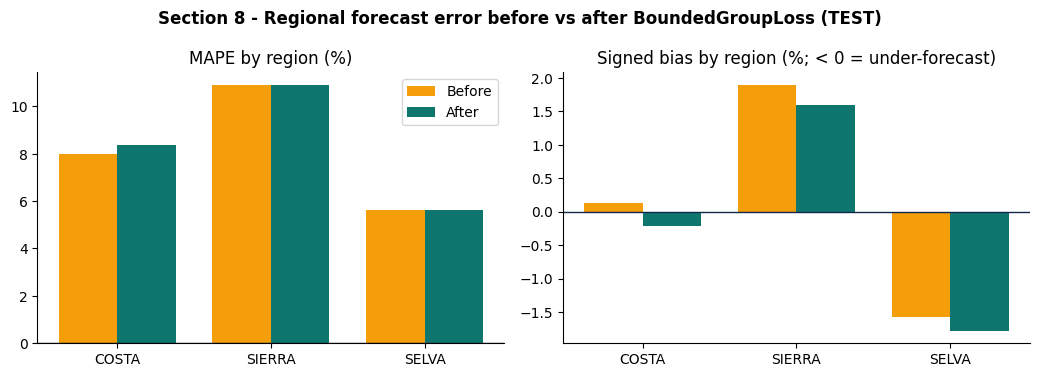

Ten stations with the largest test error (diagnostic only):


,region,name,n,MAPE_before,MAPE_after
0,SIERRA,Uchumayo-Concesión,12,57.10,57.97
1,COSTA,Nasca,10,40.00,40.11
2,SIERRA,Cátac,2,36.88,34.19
3,SIERRA,Chalhuapuquio (El Pedregal),12,30.68,30.16
4,COSTA,Matarani Concesión,12,20.35,21.37
5,COSTA,Chilca,12,14.35,15.06
6,COSTA,Santa,12,14.23,13.83
7,COSTA,Quilca,12,12.87,13.51
8,COSTA,Cuculí (Pomalca),10,12.67,13.93
9,COSTA,Punta Bombón,12,12.25,12.64


In [13]:
compare = pd.DataFrame({"Before": before, "After": after})
compare["Change"] = compare["After"] - compare["Before"]
display(compare.round(3))

acc_cost = after["MAPE overall (%)"] - before["MAPE overall (%)"]
print(f"Error-parity ratio moved {after['Error-parity ratio (Costa/Interior)'] - before['Error-parity ratio (Costa/Interior)']:+.3f} (1.0 is parity).")
print(f"Overall MAPE changed {acc_cost:+.3f} pp (positive = less accurate).")
print(f"Error-parity screening: {parity_flag(before['Error-parity ratio (Costa/Interior)'])}  ->  "
      f"{parity_flag(after['Error-parity ratio (Costa/Interior)'])}")
OVERSHOOT = []
for k in ["MAPE difference (Interior-Costa, pp)", "Bias difference (Interior-Costa, pp)"]:
    if np.sign(before[k]) != np.sign(after[k]) and abs(after[k]) > 1e-9:
        OVERSHOOT.append(k)
        print(f"NOTE: {k} crossed zero ({before[k]:+.3f} -> {after[k]:+.3f}). The mitigation overcorrected.")

med = TEST.assign(b=abs_pct_error(TEST["y"], pred_te_base), a=abs_pct_error(TEST["y"], pred_te_mit)).groupby("region")[["b", "a"]].median()
reg_cmp = pd.DataFrame({"MAPE before": before_reg3["MAPE"], "MAPE after": after_reg3["MAPE"],
                        "Median APE before": med["b"], "Median APE after": med["a"],
                        "MPE before": before_reg3["MPE"], "MPE after": after_reg3["MPE"],
                        "n": before_reg3["n"]}).reindex([r for r in REGION_MAP if r in before_reg3.index])
display(reg_cmp.round(2))

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
x = np.arange(len(reg_cmp)); w = 0.38
for a, (cb, ca, ttl) in zip(ax, [("MAPE before", "MAPE after", "MAPE by region (%)"),
                                ("MPE before", "MPE after", "Signed bias by region (%; < 0 = under-forecast)")]):
    a.bar(x - w/2, reg_cmp[cb], w, label="Before", color="#F59E0B")
    a.bar(x + w/2, reg_cmp[ca], w, label="After", color="#0F766E")
    a.axhline(0, color="#12284B", lw=1); a.set_xticks(x, reg_cmp.index); a.set_title(ttl)
ax[0].legend()
fig.suptitle("Section 8 - Regional forecast error before vs after BoundedGroupLoss (TEST)", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "F2_before_after_by_region.png", dpi=200); plt.show()

# Station-level diagnostic (12 test months per station: noisy, not the audit unit)
st = TEST.assign(ape_b=abs_pct_error(TEST["y"], pred_te_base), ape_a=abs_pct_error(TEST["y"], pred_te_mit))
STATIONS = (st.groupby(["region", "name"]).agg(n=("y", "size"), MAPE_before=("ape_b", "mean"), MAPE_after=("ape_a", "mean"))
              .sort_values("MAPE_before", ascending=False).reset_index())
print("Ten stations with the largest test error (diagnostic only):")
display(STATIONS.head(10).round(2))

## 9. Is the change real, or is it noise?
Random splits would leak the future into training, so the time-series equivalent of the workshop's 10 random splits is used:

* **10 rolling origins.** The whole pipeline (split, baseline, bound selection on validation, mitigation) is re-run with the forecast origin moved back 0, 3, 6, ..., 27 months, so each of the 10 runs has its own TRAIN / VALIDATION / TEST partition and a full 12-month test window. The earliest test window starts in 2023-01, so no validation or test window touches the COVID period. Consecutive windows share 9 months, just as the workshop's 10 random splits share most rows; overlap makes the spread smaller, so the 2-sd rule below is lenient, and a change that fails it is clearly noise.
* **Cluster bootstrap** on the main test year. Toll stations are resampled with replacement within each region (1 000 replicates) to obtain 95 % intervals for the before/after numbers and for their paired change.

Rule (same as the workshop): a change counts as **robust** only if its mean paired change across the 10 origins exceeds twice its standard deviation.

,origin,factor,before_MAPE overall (%),before_Error-parity ratio (Costa/Interior),"before_MAPE difference (Interior-Costa, pp)",after_MAPE overall (%),after_Error-parity ratio (Costa/Interior),"after_MAPE difference (Interior-Costa, pp)"
0,2025-04..2026-03,1.0,8.538,0.850,1.404,8.758,0.890,1.031
1,2025-01..2025-12,1.0,7.012,0.937,0.462,7.245,0.977,0.167
2,2024-10..2025-09,1.0,7.531,0.968,0.246,7.706,1.013,-0.096
3,2024-07..2025-06,1.0,7.901,0.953,0.385,7.979,0.981,0.155
4,2024-04..2025-03,1.0,8.741,0.962,0.337,8.754,0.966,0.303
5,2024-01..2024-12,0.7,11.578,0.545,7.317,11.583,0.551,7.181
6,2023-10..2024-09,1.0,11.161,0.512,7.805,11.084,0.499,8.065
7,2023-07..2024-06,1.0,10.894,0.523,7.390,10.781,0.503,7.758
8,2023-04..2024-03,1.0,11.220,0.490,8.346,11.104,0.474,8.646
9,2023-01..2023-12,1.0,15.894,0.710,5.656,16.026,0.701,5.900


,Before mean,Before sd,After mean,After sd,Mean change
MAPE overall (%),10.047,2.666,10.102,2.620,0.055
Error-parity ratio (Costa/Interior),0.745,0.210,0.756,0.231,0.011
"MAPE difference (Interior-Costa, pp)",3.935,3.627,3.911,3.868,-0.024
"Bias difference (Interior-Costa, pp)",3.280,3.538,3.433,3.633,0.152
Worst-region MAPE (%),14.868,6.109,14.907,6.163,0.039


  MAPE overall (%)                         mean paired change +0.055, sd 0.133  ->  not distinguishable from noise
  Error-parity ratio (Costa/Interior)      mean paired change +0.011, sd 0.026  ->  not distinguishable from noise
  MAPE difference (Interior-Costa, pp)     mean paired change -0.024, sd 0.291  ->  not distinguishable from noise
  Bias difference (Interior-Costa, pp)     mean paired change +0.152, sd 0.164  ->  not distinguishable from noise
  Worst-region MAPE (%)                    mean paired change +0.039, sd 0.104  ->  not distinguishable from noise


,Metric,Before,Before 95% CI,After,After 95% CI,Change 95% CI
0,Error-parity ratio (Costa/Interior),0.850460,"[0.565, 1.292]",0.890123,"[0.592, 1.350]","[+0.022, +0.069]"
1,"MAPE difference (Interior-Costa, pp)",1.404080,"[-2.098, 5.731]",1.030900,"[-2.482, 5.413]","[-0.509, -0.237]"
2,"Bias difference (Interior-Costa, pp)",0.781829,"[-2.392, 5.204]",0.856166,"[-2.294, 5.310]","[-0.021, +0.162]"


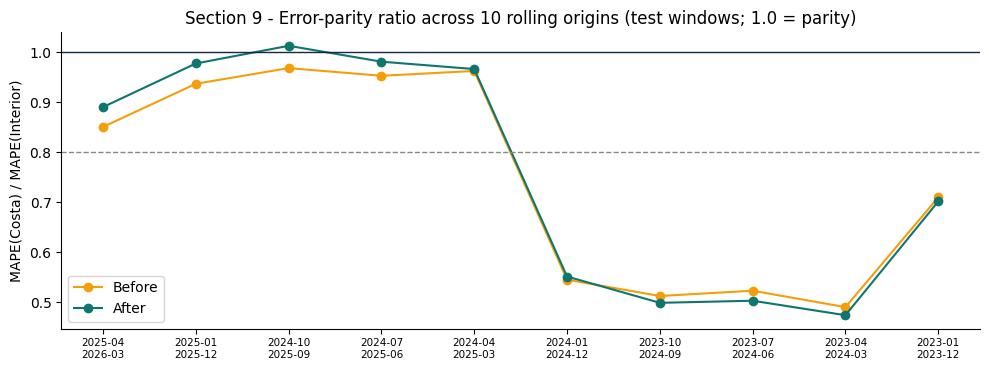

In [14]:
rows = []
for k in range(CONFIG["N_ORIGINS"]):
    tr_k, va_k, te_k, (v0k, t0k, t1k) = split_masks(M, shift_months=CONFIG["ORIGIN_STEP_MONTHS"] * k)
    if tr_k.sum() < 200 or te_k.sum() == 0: continue
    prep_k = fit_preprocess(M.loc[tr_k, FEATURES])
    Xtr_k, Xva_k, Xte_k = prep_k(M.loc[tr_k, FEATURES]), prep_k(M.loc[va_k, FEATURES]), prep_k(M.loc[te_k, FEATURES])
    y_k = M.loc[tr_k, "logy"].values
    b_k = Ridge(alpha=CONFIG["RIDGE_ALPHA"]).fit(Xtr_k, y_k)
    pick_k, _, _, _ = select_mitigation(Xtr_k, y_k, M.loc[tr_k, "region"].values, Xva_k,
                                        M.loc[va_k].reset_index(drop=True), b_k)
    TE_k = M.loc[te_k].reset_index(drop=True)
    hb, _, _ = audit_regression(TE_k, to_veh(b_k.predict(Xte_k)))
    ha, _, _ = audit_regression(TE_k, to_veh(predict_avg(pick_k["model"], Xte_k)))
    rows.append({"origin": f"{t0k:%Y-%m}..{t1k:%Y-%m}", "factor": pick_k["factor"],
                 **{f"before_{m}": v for m, v in hb.items()}, **{f"after_{m}": v for m, v in ha.items()}})
ROLL = pd.DataFrame(rows)
KEYS = list(before)
ROLL_SUMMARY = pd.DataFrame({
    "Before mean": [ROLL[f"before_{k}"].mean() for k in KEYS], "Before sd": [ROLL[f"before_{k}"].std() for k in KEYS],
    "After mean": [ROLL[f"after_{k}"].mean() for k in KEYS], "After sd": [ROLL[f"after_{k}"].std() for k in KEYS],
}, index=KEYS)
ROLL_SUMMARY["Mean change"] = ROLL_SUMMARY["After mean"] - ROLL_SUMMARY["Before mean"]
display(ROLL[["origin", "factor"] + [f"before_{k}" for k in KEYS[:3]] + [f"after_{k}" for k in KEYS[:3]]].round(3))
display(ROLL_SUMMARY.round(3))

VERDICTS = {}
for k in KEYS:
    d = ROLL[f"after_{k}"] - ROLL[f"before_{k}"]
    mc, sd = d.mean(), d.std()
    VERDICTS[k] = "robust" if abs(mc) > 2 * sd else "not distinguishable from noise"
    print(f"  {k:40s} mean paired change {mc:+.3f}, sd {sd:.3f}  ->  {VERDICTS[k]}")

# Cluster bootstrap on the main test year (resample stations within region)
rng = np.random.default_rng(SEED)
S = st.assign(spe_b=signed_pct_error(st["y"], pred_te_base), spe_a=signed_pct_error(st["y"], pred_te_mit))
per = S.groupby(["region", "station"]).agg(n=("y", "size"), ab=("ape_b", "sum"), aa=("ape_a", "sum"),
                                            sb=("spe_b", "sum"), sa=("spe_a", "sum")).reset_index()
groups_idx = {r: per.index[per["region"] == r].values for r in per["region"].unique()}
def boot_stats(idx):
    q = per.loc[idx]
    c = q[q["region"] == REF]; i = q[q["region"] != REF]
    out = {}
    for tag in ("b", "a"):
        mc_, mi_ = c[f"a{tag}"].sum() / c["n"].sum(), i[f"a{tag}"].sum() / i["n"].sum()
        bc_, bi_ = c[f"s{tag}"].sum() / c["n"].sum(), i[f"s{tag}"].sum() / i["n"].sum()
        out[tag] = (mc_ / mi_, mi_ - mc_, bi_ - bc_)
    return out
B = []
for _ in range(CONFIG["N_BOOT"]):
    idx = np.concatenate([rng.choice(v, size=len(v), replace=True) for v in groups_idx.values()])
    o = boot_stats(idx)
    B.append([*o["b"], *o["a"]])
B = np.array(B)
names = ["Error-parity ratio (Costa/Interior)", "MAPE difference (Interior-Costa, pp)", "Bias difference (Interior-Costa, pp)"]
BOOT = pd.DataFrame({
    "Metric": names,
    "Before": [before[n] for n in names], "Before 95% CI": [f"[{np.percentile(B[:, j], 2.5):.3f}, {np.percentile(B[:, j], 97.5):.3f}]" for j in range(3)],
    "After": [after[n] for n in names], "After 95% CI": [f"[{np.percentile(B[:, 3 + j], 2.5):.3f}, {np.percentile(B[:, 3 + j], 97.5):.3f}]" for j in range(3)],
    "Change 95% CI": [f"[{np.percentile(B[:, 3 + j] - B[:, j], 2.5):+.3f}, {np.percentile(B[:, 3 + j] - B[:, j], 97.5):+.3f}]" for j in range(3)],
})
display(BOOT)

fig, ax = plt.subplots(figsize=(10, 3.8))
xs = np.arange(len(ROLL))
ax.plot(xs, ROLL["before_Error-parity ratio (Costa/Interior)"], "o-", color="#F59E0B", label="Before")
ax.plot(xs, ROLL["after_Error-parity ratio (Costa/Interior)"], "o-", color="#0F766E", label="After")
ax.axhline(1.0, color="#12284B", lw=1); ax.axhline(0.8, color="#8a8984", lw=1, ls="--")
ax.set_xticks(xs, ROLL["origin"].str.replace("..", "\n", regex=False), fontsize=7.5); ax.set_ylabel("MAPE(Costa) / MAPE(Interior)")
ax.set_title(f"Section 9 - Error-parity ratio across {len(ROLL)} rolling origins (test windows; 1.0 = parity)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "F3_rolling_origin_parity.png", dpi=200); plt.show()

## 10. Cross-check with a second implementation, and the trap inside it
* **Second implementation.** The regional MAPE from Fairlearn's `MetricFrame` is recomputed with a plain `pandas` group-by and must match exactly.
* **The scale trap.** Fairlearn will compute any metric you hand it, including the wrong one. `VEH_IMD` differs by orders of magnitude between stations, so the **mean absolute error in vehicles** mostly measures traffic *volume*: a high-volume coastal station has a large MAE even when its forecast is relatively excellent. My first draft compared MAE across groups. The cell below shows how the ranking of regions changes between MAE (vehicles) and MAPE (percent). This is the regression version of the workshop's "two rulers" warning.

In [15]:
pd_check = (TEST.assign(ape=abs_pct_error(TEST["y"], pred_te_mit)).groupby("region")["ape"].mean())
fl_check = after_reg3["MAPE"]
assert np.allclose(pd_check.reindex(fl_check.index).values, fl_check.values), "Fairlearn and pandas disagree"
print("Fairlearn MetricFrame and pandas group-by agree on every regional MAPE (after mitigation).")

trap = pd.DataFrame({"MAE (vehicles/day)": before_reg3["MAE"], "MAPE (%)": before_reg3["MAPE"],
                     "Median VEH_IMD": TEST.groupby("region")["y"].median()})
trap["Rank by MAE (1 = worst)"] = trap["MAE (vehicles/day)"].rank(ascending=False).astype(int)
trap["Rank by MAPE (1 = worst)"] = trap["MAPE (%)"].rank(ascending=False).astype(int)
SCALE_TRAP = trap.reindex([r for r in REGION_MAP if r in trap.index])
display(SCALE_TRAP.round(2))
same = (SCALE_TRAP["Rank by MAE (1 = worst)"] == SCALE_TRAP["Rank by MAPE (1 = worst)"]).all()
print("MAE and MAPE rank the regions", "identically." if same else "DIFFERENTLY: an MAE-based audit would name the wrong region.")

Fairlearn MetricFrame and pandas group-by agree on every regional MAPE (after mitigation).


,MAE (vehicles/day),MAPE (%),Median VEH_IMD,Rank by MAE (1 = worst),Rank by MAPE (1 = worst)
COSTA,377.79,7.99,3124.0,1,2
SIERRA,206.36,10.89,1426.5,2,1
SELVA,60.30,5.62,965.5,3,3


MAE and MAPE rank the regions DIFFERENTLY: an MAE-based audit would name the wrong region.


## 11. (Classification branch) AIF360
The toolkit rule says: **binary target → AIF360**. `VEH_IMD` is continuous, so this branch is skipped automatically. It is kept so that the same notebook applies to a classification version of my project (for example, "will the station's traffic fall below its seasonal level?").

In [16]:
def run_classification_audit_aif360(frame, label_col, protected_col, privileged_value, favorable_label, feature_cols):
    """Workshop protocol with AIF360: baseline logistic regression, Reweighing, before/after metrics."""
    from aif360.datasets import BinaryLabelDataset
    from aif360.metrics import ClassificationMetric
    from aif360.algorithms.preprocessing import Reweighing
    from sklearn.linear_model import LogisticRegression
    df_ = frame[feature_cols + [label_col]].copy()
    df_["prot"] = (frame[protected_col] == privileged_value).astype(int)
    ds = BinaryLabelDataset(df=df_.dropna(), label_names=[label_col], protected_attribute_names=["prot"],
                            favorable_label=favorable_label, unfavorable_label=1 - favorable_label)
    trn, tst = ds.split([0.7], shuffle=True, seed=SEED)
    priv, unpriv = [{"prot": 1}], [{"prot": 0}]
    sc = StandardScaler().fit(trn.features)
    def fit_eval(weights=None):
        clf = LogisticRegression(max_iter=1000).fit(sc.transform(trn.features), trn.labels.ravel(), sample_weight=weights)
        pred = tst.copy(deepcopy=True); pred.labels = clf.predict(sc.transform(tst.features)).reshape(-1, 1)
        cm = ClassificationMetric(tst, pred, unprivileged_groups=unpriv, privileged_groups=priv)
        return {"Accuracy": cm.accuracy(), "Disparate impact": cm.disparate_impact(),
                "Statistical parity diff": cm.statistical_parity_difference(),
                "Equal opportunity diff": cm.equal_opportunity_difference(),
                "Average odds diff": cm.average_odds_difference()}
    rw = Reweighing(unprivileged_groups=unpriv, privileged_groups=priv).fit_transform(trn)
    return pd.DataFrame({"Before": fit_eval(), "After (Reweighing)": fit_eval(rw.instance_weights)})

if TASK_TYPE == "classification":
    display(run_classification_audit_aif360(M, "y", "region", REF, 1, FEATURES))
else:
    print(f"Skipped: TASK_TYPE = '{TASK_TYPE}', so the audit uses {TOOLKIT} (Sections 6-10).")

Skipped: TASK_TYPE = 'regression', so the audit uses Microsoft Fairlearn (Sections 6-10).


## 12. Write your Bias Audit Report
The report is generated in **English** as a Word document from the numbers of this run (Sections 3-10). It follows the seven items of the deliverable slide (Session 12, slide 49): dataset, protected attribute and direction; bias already in the labels; before metrics (disparate impact counterpart plus two others); the fix and why; the before/after table; the cost and whether it survives 10 splits; a recommendation and honest limitations. A Markdown preview is shown below, and the `.docx`, figures and tables are saved to the results folder and downloaded.

In [17]:
from docx import Document
from docx.shared import Pt, Cm, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.oxml.ns import qn
from docx.oxml import OxmlElement

f3 = lambda v: f"{v:.3f}"
f2 = lambda v: f"{v:.2f}"
sg = lambda v, d=2: f"{v:+.{d}f}"
R_B, R_A = before["Error-parity ratio (Costa/Interior)"], after["Error-parity ratio (Costa/Interior)"]
D_B, D_A = before["MAPE difference (Interior-Costa, pp)"], after["MAPE difference (Interior-Costa, pp)"]
BI_B, BI_A = before["Bias difference (Interior-Costa, pp)"], after["Bias difference (Interior-Costa, pp)"]
W_B, W_A = before["Worst-region MAPE (%)"], after["Worst-region MAPE (%)"]
A_B, A_A = before["MAPE overall (%)"], after["MAPE overall (%)"]
worst_before = before_reg3["MAPE"].idxmax(); worst_after = after_reg3["MAPE"].idxmax()
interior_worse = D_B > 0
under_interior = BI_B < 0
regions_present = list(reg_cmp.index)
n_stations = {r: int(DATA_BIAS.set_index("Region").loc[r, "stations"]) for r in regions_present}
smallest = min(n_stations, key=n_stations.get)
robust_parity = VERDICTS["Error-parity ratio (Costa/Interior)"] == "robust"
robust_worst = VERDICTS["Worst-region MAPE (%)"] == "robust"
robust_acc = VERDICTS["MAPE overall (%)"] == "robust"
chg_ci = dict(zip(BOOT["Metric"], BOOT["Change 95% CI"]))
improved_parity = R_A > R_B
improved_worst = W_A < W_B

def sentence_direction_OLD():
    if interior_worse:
        s = (f"Before mitigation the Interior received less accurate forecasts than the coast: MAPE difference "
             f"{sg(D_B)} percentage points and an error-parity ratio of {f3(R_B)}")
        s += ", below the 0.8 screening value." if R_B < 0.8 else ", above the 0.8 screening value."
    else:
        s = (f"Before mitigation the Interior was not forecast less accurately than the coast (MAPE difference "
             f"{sg(D_B)} pp, error-parity ratio {f3(R_B)}); the accuracy gap runs against the reference group.")
    s += (f" The signed bias difference was {sg(BI_B)} pp, so the Interior was "
          + ("under-forecast more than the coast, which is the harmful direction." if under_interior
             else "not under-forecast relative to the coast."))
    return s

def sentence_feasibility():
    s = (f"Only {N_FEASIBLE} of the {len(cand)} candidate bounds was feasible for a single shared Ridge model. " if N_FEASIBLE == 1 else
         f"{N_FEASIBLE} of the {len(cand)} candidate bounds were feasible for a single shared Ridge model. ")
    if 0 < N_FEASIBLE < len(cand):
        s += (f"Tighter bounds could not bind: the worst region's training loss stayed at {cand['train_worst_region_loss'].min():.4f} "
              f"log units, above bounds of {cand.loc[~cand['feasible'], 'bound_log_loss'].max():.4f} or less, so the selected model "
              "is almost the baseline. ")
    if N_FEASIBLE == 0:
        s += (f"Even with the largest Lagrange weight on the worst region, its training loss stayed at "
              f"{base_tr_loss_reg.max():.4f} log units against bounds of {cand['bound_log_loss'].min():.4f} to "
              f"{cand['bound_log_loss'].max():.4f}, so the constraint could not bind. ")
    s += (f"The reducibility check shows that a model fitted to the worst validation region alone ({worst_r.title()}) changes its "
          f"validation MAPE by {WORST_REDUCIBLE:+.1f}%, ")
    s += ("so a meaningful part of the gap is caused by pooling all regions into one model." if WORST_REDUCIBLE < -5 else
          "so most of the gap is irreducible for this model class: it reflects the region's volatility, not a pooled model.")
    return s

def sentence_direction():
    order = before_reg3["MAPE"].sort_values(ascending=False)
    others = ", ".join(f"{r.title()} {f2(v)}%" for r, v in order.items() if r != worst_before)
    s = (f"Before mitigation the worst-served region was {worst_before.title()}, with a MAPE of {f2(order.iloc[0])}% "
         f"(against {others}). Pooled as the Interior, Sierra and Selva had a MAPE {sg(D_B)} pp "
         + ("above" if D_B > 0 else "below") + f" the coast and an error-parity ratio of {f3(R_B)}, "
         + ("above" if R_B >= 0.8 else "below") + " the 0.8 screening value")
    if "SELVA" in before_reg3.index and "SIERRA" in before_reg3.index and \
       (before_reg3.loc["SELVA", "MAPE"] - before_reg3.loc[REF, "MAPE"]) * (before_reg3.loc["SIERRA", "MAPE"] - before_reg3.loc[REF, "MAPE"]) < 0:
        s += "; pooling hides the difference, because the two interior regions sit on opposite sides of the coast"
    s += ". "
    under = [r for r in regions_present if before_reg3.loc[r, "MPE"] < 0]
    if under:
        s += ("In the harmful direction, " + " and ".join(f"{r.title()} (signed bias {sg(before_reg3.loc[r, 'MPE'])}%)" for r in under)
              + (" is" if len(under) == 1 else " are") + " under-forecast on average; the other regions are over-forecast.")
    else:
        s += "No region is under-forecast on average, so the harmful direction of error does not appear at the regional level."
    return s

def sentence_effect():
    s = (f"The mitigation moved the worst-region MAPE from {f2(W_B)}% to {f2(W_A)}% and the error-parity ratio from "
         f"{f3(R_B)} to {f3(R_A)}, while overall MAPE changed by {sg(A_A - A_B)} pp.")
    if not improved_worst and not improved_parity:
        s += " On the held-out test year the mitigation did not improve the worst-served region."
    return s

def sentence_uncertainty():
    robust = [k for k, v in VERDICTS.items() if v == "robust"]
    s = (f"None of the five changes exceeds twice its spread across the {len(ROLL)} rolling origins, so none is a finding. " if not robust else
         f"Across the {len(ROLL)} rolling origins, the change in " + ", ".join(robust) + " is robust; the rest are within noise. ")
    rb = ROLL["before_Error-parity ratio (Costa/Interior)"]
    s += (f"The gap itself moves between origins: the baseline error-parity ratio ranged from {f3(rb.min())} "
          f"({ROLL.loc[rb.idxmin(), 'origin']}) to {f3(rb.max())} ({ROLL.loc[rb.idxmax(), 'origin']}), a larger swing than any mitigation effect. ")
    ra = ROLL["after_Error-parity ratio (Costa/Interior)"]
    nfb, nfa = int((rb < 0.8).sum()), int((ra < 0.8).sum())
    if nfb:
        fl = ROLL.loc[rb < 0.8, "origin"]
        s += (f"The baseline fails the 0.8 screen at {nfb} of the {len(ROLL)} origins (test windows {fl.iloc[-1].split('..')[0]} to "
              f"{fl.iloc[0].split('..')[1]}), where Interior forecasts carry roughly twice the coast's relative error; after mitigation "
              f"{nfa} of {len(ROLL)} still fail, so the constraint does not remove the flag where it matters. ")
    else:
        s += f"The baseline passes the 0.8 screen at all {len(ROLL)} origins. "
    b_ci = BOOT.set_index("Metric").loc["Error-parity ratio (Costa/Interior)", "Before 95% CI"]
    lo_, hi_ = [float(x) for x in b_ci.strip("[]").split(",")]
    s += (f"On the main test year the station bootstrap places the baseline error-parity ratio in {b_ci}, an interval that "
          + ("includes 1.0, so the regional gap of that year is not statistically clear on its own; " if lo_ <= 1 <= hi_ else "excludes 1.0; ")
          + f"the paired change after mitigation, {chg_ci['Error-parity ratio (Costa/Interior)']}, is consistent within that year but "
          "small next to the variation between origins.")
    return s

def recommendation():
    recs = []
    if robust_parity and improved_parity and not (robust_acc and A_A > A_B):
        recs.append("Adopt the bounded-group-loss model for regional planning, because it narrows the accuracy gap between "
                    "regions at an overall cost that does not survive resampling; re-audit every quarter with the same split protocol.")
    else:
        recs.append("Do not replace the baseline on fairness grounds alone: the regional gains are not robust across the rolling origins. "
                    "Keep the baseline, publish its regional error table, and treat the bounded-group-loss model as an experiment.")
    if WORST_REDUCIBLE >= -5:
        recs.append("Address the gap upstream rather than in the loss function: because region-specific models do not lower the worst "
                    "region's error, the remedy is better data (more stations and covariates that explain volatility, such as road "
                    "closures, landslides and strikes) and wider prediction intervals for that region, not a fairness constraint.")
    else:
        recs.append("Test a model with region-specific dynamics (interaction terms or one model per region) as the next mitigation, "
                    "since the reducibility check shows that pooling all regions into one model costs the worst region accuracy.")
    recs.append(f"Before any planning use, report MAPE and signed bias per region with intervals, and increase coverage of the "
                f"least represented region ({smallest.title()}, {n_stations[smallest]} stations), whose estimates carry the widest uncertainty.")
    return recs

LIMITS = [
    "Region is read from the national route for longitudinal roads, but transversal tolls take their department's predominant "
    "region (two documented overrides), and transversal roads climb from coast to highlands, so a few tolls remain approximate.",
    "Error disparity between regions is not evidence of discrimination against people; it is a risk of unequal service "
    "when forecasts drive investment, and the causal link to allocation decisions was not tested.",
    "Only one model family (Ridge on log traffic, one-month horizon) was audited; the gradient-boosting models and longer "
    "horizons of my ITFF pipeline may behave differently.",
    "Intersectional and finer cells (region x vehicle class, region x station size) were not examined, and stations "
    "with fewer than 12 test months weigh less in the regional averages.",
]
SUMMARY_FEAS = ("" if N_FEASIBLE else " The bound was infeasible for one shared model; the reducibility check indicates that the "
                + ("gap is partly caused by pooling." if WORST_REDUCIBLE < -5 else "gap mostly reflects regional volatility."))
med_gap_s = reg_cmp.loc[worst_before, "Median APE before"] - reg_cmp.loc[REF, "Median APE before"]
any_robust = any(v == "robust" for v in VERDICTS.values())
SUMMARY = (f"I audited a one-month-ahead traffic forecasting model (Ridge regression on log VEH_IMD) trained on {COVERAGE['stations']} "
           f"toll stations of Peru's National Road Network for unequal forecast quality between natural regions. "
           f"{worst_before.title()} received the least accurate forecasts (MAPE {f2(before_reg3.loc[worst_before, 'MAPE'])}% against "
           f"{f2(before_reg3.loc[REF, 'MAPE'])}% on the coast), but its median error is only {sg(med_gap_s)} pp above the coast's, "
           "so much of the gap comes from a few stations with structural breaks. Fairlearn's ExponentiatedGradient with a "
           "BoundedGroupLoss constraint " + (f"moved the worst-region MAPE from {f2(W_B)}% to {f2(W_A)}% and overall MAPE by {sg(A_A - A_B)} pp."
           ) + SUMMARY_FEAS + " " + (f"No change survived the {len(ROLL)} rolling origins. " if not any_robust else "")
           + ("The audit points to data, not to the model, as the lever for regional fairness: a region's error is set by its "
              "volatility and by station-level breaks, which a constraint on the loss function cannot remove." if (not any_robust and WORST_REDUCIBLE >= -5)
              else "The robust changes are reported in Section 6."))

doc = Document()
st_ = doc.styles["Normal"]; st_.font.name = "Arial"; st_.font.size = Pt(10.5)
st_.element.rPr.rFonts.set(qn("w:eastAsia"), "Arial")
for s in doc.sections:
    s.page_width, s.page_height = Cm(21.59), Cm(27.94)
    s.left_margin = s.right_margin = s.top_margin = s.bottom_margin = Cm(1.9)
NAVY = RGBColor(0x12, 0x28, 0x4B); TEAL = RGBColor(0x0F, 0x76, 0x6E)

def para(text, bold_lead=None, size=None, italic=False, align=WD_ALIGN_PARAGRAPH.JUSTIFY, after=6):
    p = doc.add_paragraph(); p.alignment = align; p.paragraph_format.space_after = Pt(after)
    if bold_lead:
        r = p.add_run(bold_lead + " "); r.bold = True
        if size: r.font.size = Pt(size)
    r = p.add_run(text); r.italic = italic
    if size: r.font.size = Pt(size)
    return p
def heading(text, level=1):
    h = doc.add_heading(text, level=level)
    for r in h.runs: r.font.name = "Arial"; r.font.color.rgb = NAVY if level == 1 else TEAL; r.font.size = Pt(13 if level == 1 else 11)
    h.paragraph_format.keep_with_next = True
def shade(cell, hex_fill):
    tcPr = cell._tc.get_or_add_tcPr(); shd = OxmlElement("w:shd")
    shd.set(qn("w:val"), "clear"); shd.set(qn("w:color"), "auto"); shd.set(qn("w:fill"), hex_fill); tcPr.append(shd)
def table(header, rows, widths=None):
    t = doc.add_table(rows=1, cols=len(header)); t.style = "Table Grid"; t.autofit = False
    for i, h in enumerate(header):
        c = t.rows[0].cells[i]; c.text = ""; r = c.paragraphs[0].add_run(str(h)); r.bold = True
        r.font.size = Pt(9); r.font.color.rgb = RGBColor(0xFF, 0xFF, 0xFF); shade(c, "12284B")
    for k, row in enumerate(rows):
        cells = t.add_row().cells
        for i, v in enumerate(row):
            cells[i].text = ""; r = cells[i].paragraphs[0].add_run(str(v)); r.font.size = Pt(9)
            if k % 2: shade(cells[i], "F2F2F2")
    widths = widths or [17.6 / len(header)] * len(header)
    grid = t._tbl.tblGrid
    for i, gc in enumerate(grid.findall(qn("w:gridCol"))): gc.set(qn("w:w"), str(int(widths[i] * 567)))
    for i, col in enumerate(t.columns): col.width = Cm(widths[i])
    for k, row in enumerate(t.rows):
        for i, wd in enumerate(widths): row.cells[i].width = Cm(wd)
        trPr = row._tr.get_or_add_trPr(); trPr.append(OxmlElement("w:cantSplit"))
        if k == 0:
            th = OxmlElement("w:tblHeader"); trPr.append(th)
        if k < len(t.rows) - 1:
            for c in row.cells:
                for pp in c.paragraphs: pp.paragraph_format.keep_with_next = True
    doc.add_paragraph().paragraph_format.space_after = Pt(2)
def bullet(text, lead=None):
    p = doc.add_paragraph(style="List Bullet"); p.alignment = WD_ALIGN_PARAGRAPH.JUSTIFY
    if lead: r = p.add_run(lead + " "); r.bold = True
    p.add_run(text)
def figure(path, caption, width_cm=16):
    doc.add_picture(str(path), width=Cm(width_cm)); doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER
    doc.paragraphs[-1].paragraph_format.keep_with_next = True
    para(caption, italic=True, size=8.5, align=WD_ALIGN_PARAGRAPH.LEFT, after=10)

t = doc.add_paragraph(); r = t.add_run("Bias Audit Report: Regional Fairness of a Toll-Traffic Forecasting Model")
r.bold = True; r.font.size = Pt(16); r.font.color.rgb = NAVY
t = doc.add_paragraph(); r = t.add_run("MTC toll-station traffic (VEH_IMD) · regression audit with Microsoft Fairlearn · sensitive attribute: natural macro-region")
r.font.size = Pt(10.5); r.font.color.rgb = TEAL
for line in [f"Session 12 Workshop | {CONFIG['COURSE']} | {CONFIG['PROGRAM']}",
             f"Instructor: {CONFIG['INSTRUCTOR']} | Student: {CONFIG['STUDENT']} (Student Code: {CONFIG['STUDENT_CODE']}) | {datetime.date.today():%B %Y}",
             f"Toolkits: Fairlearn {fairlearn.__version__}, scikit-learn {sklearn.__version__} | Notebook: Session12_MTC_Bias_Audit_EVANGELISTA_GAMARRA_MOISES.ipynb"]:
    para(line, size=9, align=WD_ALIGN_PARAGRAPH.LEFT, after=1)
para("", after=4)
para(SUMMARY, bold_lead="Summary.")

heading("1. Dataset, task and audit groups")
table(["Item", "Value"], [
    ["Dataset", f"MTC, \"Flujo Vehicular Registrado en las Unidades de Peaje de la Red Vial Nacional\" (Peru National Open Data Portal): "
                f"{COVERAGE['rows_in_file']:,} rows, {COVERAGE['stations']} toll stations, {COVERAGE['date_min']} to {COVERAGE['date_max']}"],
    ["Data provenance", f"{DATA} (uploaded and versioned with Git), MD5 {DATA_MD5}; source URL in data/DATA_MANIFEST.json"],
    ["Cleaning", f"{COVERAGE['duplicate_station_months_aggregated']} duplicate station-months (administration changes) summed; "
                 f"{COVERAGE['zero_traffic_months_removed']} station-months with VEH_IMD = 0 (no operation) removed"],
    ["Prediction task", "Regression: VEH_IMD (average daily vehicles) of each toll station, one month ahead"],
    ["Toolkit", "Microsoft Fairlearn (MetricFrame, ExponentiatedGradient, BoundedGroupLoss), because the target is continuous; "
                "AIF360 is reserved for binary targets"],
    ["Sensitive attribute", "Natural macro-region of the road each toll serves: " + ", ".join(r.title() for r in regions_present) +
                            ". Longitudinal routes by axis (PE-1 Costa, PE-3 Sierra, PE-5 Selva, read from CODIGO_PEAJE); transversal routes by "
                            "department; " + ", ".join(f"{k} -> {v.title()}" for k, v in STATION_REGION_OVERRIDE.items()) + " by documented override"],
    ["Reference group", "Costa"],
    ["Comparison group", "Interior = Sierra + Selva"],
    ["Split", f"Train until {SPLIT['train_until']}; validation {SPLIT['validation']}; test {SPLIT['test']} ({SPLIT['test_rows']:,} station-months)"],
    ["Baseline model", f"Ridge regression (alpha {CONFIG['RIDGE_ALPHA']}) on log1p(VEH_IMD) with calendar lags 1, 2, 3, 12, rolling mean, last change and month of year"],
], widths=[4, 13.5])
heading("Statement of direction", 2)
para("A regression model has no favorable label, but it has a harmful direction of error. I define the signed error as "
     "(forecast - actual) / actual, so a negative value is an under-forecast. Under-forecasting a region's traffic is the "
     "harmful direction: maintenance budgets, capacity and toll-lane staffing sized on that forecast would under-serve the "
     "region's road users. The notebook asserts this sign convention in code. Read backwards, a region that is systematically "
     "under-estimated would appear to be favoured by the model.")
para("Toll stations are not people. The audit treats region as the sensitive attribute because investment decisions informed "
     "by these forecasts reach the people who live in each region, and road investment in Peru has historically concentrated on the coast.")

heading("2. Bias present before any model exists")
table(["Region", "Stations", "Station-months", "Share of rows (%)", "Median VEH_IMD", "Median monthly volatility (%)"],
      [[r["Region"].title(), int(r["stations"]), int(r["station_months"]), f2(r["share_of_rows"]), f"{r['median_IMD']:,.0f}",
        f2(r["median_volatility"])] for _, r in DATA_BIAS.iterrows()], widths=[2.6, 2, 2.8, 3, 3, 4.1])
figure(FIG / "F1_data_bias_by_region.png", "Figure 1. Representation and forecastability by region, computed before any model was trained.")
vol_s = DATA_BIAS.set_index("Region")["median_volatility"]
para(f"The data are unbalanced before any model exists. {max(n_stations, key=n_stations.get).title()} contributes the most stations "
     f"and {smallest.title()} the fewest ({n_stations[smallest]}). The most volatile region is {vol_s.idxmax().title()} "
     f"(median monthly volatility {f2(vol_s.max())}%) and the least volatile is {vol_s.idxmin().title()} ({f2(vol_s.min())}%). "
     "A single model fitted to all stations learns mostly from the regions that dominate the rows, and volatile series are "
     "harder to forecast for any model. Both properties set a floor on the regional error that no mitigation can remove.")

heading("3. Before metrics: the unmitigated baseline")
para("A regression has no favorable label, so disparate impact and the parity differences cannot be computed directly. "
     "The audit uses their regression counterparts on forecast error, shown in the second column.")
table(["Metric", "Workshop counterpart", "Value", "Target", "Reading"], [
    ["MAPE overall (%)", "Accuracy", f2(A_B), "lower", "Average relative error of the forecasts"],
    ["Error-parity ratio, MAPE(Costa)/MAPE(Interior)", "Disparate impact (ratio)", f3(R_B), "1.0 (0.8 screen)", parity_flag(R_B)],
    ["MAPE difference, Interior - Costa (pp)", "Statistical parity difference", sg(D_B), "0", "Positive = Interior forecasts less accurate"],
    ["Bias difference, MPE Interior - MPE Costa (pp)", "Equal opportunity difference (error direction)", sg(BI_B), "0", "Negative = Interior under-forecast more"],
    ["Worst-region MAPE (%)", "-", f2(W_B), "lower", f"Worst region: {worst_before.title()}"],
], widths=[4.6, 3.6, 1.6, 2.3, 5.4])
table(["Region", "n (test)", "MAPE (%)", "Median APE (%)", "Signed bias MPE (%)", "MAE (vehicles/day)"],
      [[r.title(), int(before_reg3.loc[r, "n"]), f2(before_reg3.loc[r, "MAPE"]), f2(reg_cmp.loc[r, "Median APE before"]),
        sg(before_reg3.loc[r, "MPE"]), f"{before_reg3.loc[r, 'MAE']:,.0f}"] for r in regions_present], widths=[2.6, 2, 2.6, 3, 3.6, 3.7])
para(sentence_direction())
worst_st = STATIONS.iloc[0]
med_gap = reg_cmp.loc[worst_before, "Median APE before"] - reg_cmp.loc[REF, "Median APE before"]
para(f"The mean hides a concentration. In the worst region ({worst_before.title()}) the mean APE is {f2(before_reg3.loc[worst_before, 'MAPE'])}% "
     f"but the median is {f2(reg_cmp.loc[worst_before, 'Median APE before'])}%, against {f2(reg_cmp.loc[REF, 'Median APE before'])}% on the coast "
     f"(median gap {sg(med_gap)} pp). The largest single error belongs to {worst_st['name']} ({worst_st['region'].title()}, "
     f"MAPE {f2(worst_st['MAPE_before'])}% over {int(worst_st['n'])} months), so part of the regional gap is carried by a few stations "
     "with structural breaks rather than by every station of the region.")
para("The 0.8 value is borrowed from the four-fifths rule only as a screening heuristic; it has no legal meaning for forecast errors.", italic=True, size=9)

heading("4. Mitigation applied, and why")
table(["Design choice", "Justification"], [
    ["Method", "Fairlearn ExponentiatedGradient with a BoundedGroupLoss constraint (Agarwal, Dudík & Wu, 2019), wrapping the same Ridge model"],
    ["Family", "In-processing: the constraint enters the training objective"],
    ["Fairness criterion it targets", "Bounded group loss: the mean absolute log error of every region must stay below a bound, while the average error is minimized"],
    ["Bound selection", f"Candidates {CONFIG['BOUND_FACTORS']} x the baseline training loss; chosen on validation only (smallest worst-region MAPE "
                        f"with overall MAPE at most {int((CONFIG['MAX_OVERALL_INCREASE'] - 1) * 100)}% above the baseline). Selected factor: {CHOSEN_FACTOR}"],
    ["Deterministic predictions", "The randomized mixture is replaced by the weighted average of its Ridge models. Absolute loss is convex, so by "
                                  "Jensen's inequality each region's loss cannot exceed the mixture's expected loss; every station receives one forecast"],
    ["Alternatives considered", "Group-balanced sample weights (pre-processing, my first draft): no target metric. Region-specific bias "
                                "correction (post-processing): equalizes bias but not accuracy"],
], widths=[4, 13.5])
heading("Why this method fits this harm", 2)
para("The harm is allocative and regional: if one region's traffic is forecast poorly, decisions built on the forecast serve that "
     "region worse. A criterion that bounds the error of the worst-served region addresses that harm directly. Equalizing errors by "
     "making the best-served region worse would satisfy a parity metric without helping anyone, so I chose a minimax-style bound "
     "rather than strict parity of errors.")
heading("What I gave up by choosing it", 2)
para("Bounded group loss does not require equal errors or equal signed bias across regions, so a gap can remain after mitigation. "
     "It may also trade some average accuracy for the worst region. Because the regions differ in volatility (Section 2), "
     "exact parity of forecast errors is neither achievable nor desirable: it would mean degrading the more predictable coastal series.")

heading("5. After metrics, and the trade-off")
table(["Metric", "Before", "After", "Change"],
      [[k, f3(before[k]), f3(after[k]), sg(after[k] - before[k], 3) + (" (crossed zero)" if k in OVERSHOOT else "")] for k in KEYS],
      widths=[7.5, 3, 3, 4])
figure(FIG / "F2_before_after_by_region.png", "Figure 2. MAPE and signed bias by region on the test year, before and after the BoundedGroupLoss mitigation.")
table(["Region", "MAPE before", "MAPE after", "MPE before", "MPE after"],
      [[r.title(), f2(reg_cmp.loc[r, "MAPE before"]), f2(reg_cmp.loc[r, "MAPE after"]), sg(reg_cmp.loc[r, "MPE before"]),
        sg(reg_cmp.loc[r, "MPE after"])] for r in regions_present], widths=[3.5, 3.5, 3.5, 3.5, 3.5])
para(sentence_effect())
heading("Feasibility of the bound and reducibility of the gap", 2)
para(sentence_feasibility())
table(["Region", "Validation MAPE, pooled", "Validation MAPE, region-specific", "Relative change (%)"],
      [[r["Region"].title(), f2(r.iloc[1]), f2(r.iloc[2]), sg(r.iloc[3], 1)] for _, r in REDUCIBILITY.iterrows()],
      widths=[3.5, 4.5, 5, 4.5])
if OVERSHOOT:
    para("Overshoot: " + "; ".join(f"{k} crossed zero ({sg(before[k])} to {sg(after[k])})" for k in OVERSHOOT) +
         ". The mitigation reversed the direction of the gap, which I report rather than present as a clean improvement.")
else:
    para("No gap crossed zero: the mitigation did not reverse the direction of any regional disparity.")
para(f"Cross-check: Fairlearn's MetricFrame and an independent pandas group-by give identical regional MAPE values. "
     f"The scale trap is real in these data: ranked by MAE in vehicles the worst region is "
     f"{SCALE_TRAP['MAE (vehicles/day)'].idxmax().title()}, ranked by MAPE it is {SCALE_TRAP['MAPE (%)'].idxmax().title()}"
     + (" - the same region in this run, but only because volume and difficulty happen to coincide." if
        SCALE_TRAP['MAE (vehicles/day)'].idxmax() == SCALE_TRAP['MAPE (%)'].idxmax() else
        ". An audit based on absolute errors would have named the wrong region."))

heading("6. Uncertainty: which changes survive resampling?")
para(f"Random splits would leak future months into training, so the time-series equivalent of the workshop's 10 splits was used: "
     f"the whole pipeline (split, baseline, bound selection on validation and mitigation) was re-run at {len(ROLL)} forecast origins "
     f"spaced {CONFIG['ORIGIN_STEP_MONTHS']} months apart, with 12-month test windows from {ROLL['origin'].iloc[-1].split('..')[0]} to "
     f"{ROLL['origin'].iloc[0].split('..')[1]}. Consecutive windows share {12 - CONFIG['ORIGIN_STEP_MONTHS']} months, as random splits share rows; "
     "this overlap shrinks the spread, so the 2-sd rule is lenient and a change that fails it is clearly noise.")
table(["Metric", "Before mean", "Before sd", "After mean", "After sd", "Mean change", "Verdict"],
      [[k, f3(r["Before mean"]), f3(r["Before sd"]), f3(r["After mean"]), f3(r["After sd"]), sg(r["Mean change"], 3), VERDICTS[k]]
       for k, r in ROLL_SUMMARY.iterrows()], widths=[5, 1.9, 1.7, 1.9, 1.7, 2, 3.3])
figure(FIG / "F3_rolling_origin_parity.png", f"Figure 3. Error-parity ratio before and after mitigation at each of the {len(ROLL)} rolling origins (1.0 = parity; dashed line = 0.8 screen).", 14)
table(["Metric (main test year)", "Before [95% CI]", "After [95% CI]", "Change 95% CI"],
      [[r["Metric"], f"{f3(r['Before'])} {r['Before 95% CI']}", f"{f3(r['After'])} {r['After 95% CI']}", r["Change 95% CI"]]
       for _, r in BOOT.iterrows()], widths=[5.5, 4, 4, 4])
para(sentence_uncertainty())

heading("7. Recommendation")
for rec in recommendation(): bullet(rec)

heading("8. Honest limitations of this audit")
for lim in LIMITS: bullet(lim)

p = para(f"Closing statement of the trade-off. I chose bounded group loss because the harm I want to prevent is a region whose "
         f"traffic is forecast worse than the rest, and the protection it needs is a ceiling on its error, not a lower accuracy for "
         f"the coast. In this run the worst-region MAPE moved from {f2(W_B)}% to {f2(W_A)}% and overall MAPE by {sg(A_A - A_B)} pp. "
         f"I gave up exact parity of errors and of signed bias, and this report states which differences survived resampling and which did not.",
         italic=True)

heading("References")
for ref in [
    "Agarwal, A., Beygelzimer, A., Dudík, M., Langford, J., & Wallach, H. (2018). A reductions approach to fair classification. ICML.",
    "Agarwal, A., Dudík, M., & Wu, Z. S. (2019). Fair regression: Quantitative definitions and reduction-based algorithms. ICML.",
    "Bellamy, R. K. E., et al. (2019). AI Fairness 360: An extensible toolkit for detecting and mitigating algorithmic bias. IBM Journal of Research and Development, 63(4/5).",
    "Hyndman, R. J., & Athanasopoulos, G. (2021). Forecasting: Principles and practice (3rd ed.). OTexts.",
    "Suresh, H., & Guttag, J. (2021). A framework for understanding sources of harm throughout the machine learning life cycle. EAAMO.",
    "Weerts, H., Dudík, M., Edgar, R., Jalali, A., Lutz, R., & Madaio, M. (2023). Fairlearn: Assessing and improving fairness of AI systems. Journal of Machine Learning Research, 24(257).",
    "Ministerio de Transportes y Comunicaciones (MTC). Flujo vehicular registrado en las unidades de peaje de la Red Vial Nacional. Plataforma Nacional de Datos Abiertos del Perú.",
]:
    q = doc.add_paragraph(ref); q.paragraph_format.left_indent = Cm(0.6); q.paragraph_format.first_line_indent = Cm(-0.6)
    for r in q.runs: r.font.size = Pt(9)

REPORT = OUT / "Session12_MTC_Bias_Audit_Report_EVANGELISTA_GAMARRA_MOISES.docx"
doc.save(REPORT)

# Tables, summary and Markdown preview
compare.to_csv(OUT / "before_after_test.csv"); reg_cmp.to_csv(OUT / "by_region_test.csv")
ROLL.to_csv(OUT / "rolling_origin.csv", index=False); BOOT.to_csv(OUT / "bootstrap_ci.csv", index=False)
STATIONS.to_csv(OUT / "stations_test_diagnostic.csv", index=False); DATA_BIAS.to_csv(OUT / "data_bias_by_region.csv", index=False)
json.dump({"data_file": DATA, "data_md5": DATA_MD5, "coverage": COVERAGE, "split": SPLIT, "before": before, "after": after, "chosen_factor": CHOSEN_FACTOR,
           "verdicts": VERDICTS, "wrong_positional_lags": wrong_positional}, open(OUT / "audit_summary.json", "w"), indent=2, default=str)
display(Markdown("### Report preview\n\n**Summary.** " + SUMMARY + "\n\n**Recommendation.**\n" +
                 "\n".join(f"- {r}" for r in recommendation())))
print("Word report:", REPORT)

ZIP = OUT / "Session12_MTC_Bias_Audit_results.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for p_ in sorted(OUT.rglob("*")):
        if p_.is_file() and p_.suffix in (".docx", ".csv", ".json", ".png"): z.write(p_, p_.relative_to(OUT))
if IN_COLAB:
    from google.colab import files
    for f_ in (REPORT, ZIP):
        files.download(str(f_)); time.sleep(2)
    print("Downloads started (allow multiple downloads if the browser asks).")

### Report preview

**Summary.** I audited a one-month-ahead traffic forecasting model (Ridge regression on log VEH_IMD) trained on 82 toll stations of Peru's National Road Network for unequal forecast quality between natural regions. Sierra received the least accurate forecasts (MAPE 10.89% against 7.99% on the coast), but its median error is only +0.96 pp above the coast's, so much of the gap comes from a few stations with structural breaks. Fairlearn's ExponentiatedGradient with a BoundedGroupLoss constraint moved the worst-region MAPE from 10.89% to 10.88% and overall MAPE by +0.22 pp. No change survived the 10 rolling origins. The audit points to data, not to the model, as the lever for regional fairness: a region's error is set by its volatility and by station-level breaks, which a constraint on the loss function cannot remove.

**Recommendation.**
- Do not replace the baseline on fairness grounds alone: the regional gains are not robust across the rolling origins. Keep the baseline, publish its regional error table, and treat the bounded-group-loss model as an experiment.
- Address the gap upstream rather than in the loss function: because region-specific models do not lower the worst region's error, the remedy is better data (more stations and covariates that explain volatility, such as road closures, landslides and strikes) and wider prediction intervals for that region, not a fairness constraint.
- Before any planning use, report MAPE and signed bias per region with intervals, and increase coverage of the least represented region (Selva, 8 stations), whose estimates carry the widest uncertainty.

Word report: /content/Session12_MTC_Bias_Audit/outputs/Session12_MTC_Bias_Audit_Report_EVANGELISTA_GAMARRA_MOISES.docx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloads started (allow multiple downloads if the browser asks).
